[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LRCole3/pre-training-pathway/blob/main/06_vae_gan_autoregressive.ipynb)

# 06 · Generating Images Before Diffusion: Autoencoders, VAEs, GANs and Pixel-by-Pixel Models

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Counting and embeddings | Count n-grams; learn word vectors | A first language model; similar words get similar vectors | Fixed window; one vector per word |
| 02 | RNNs, attention, ELMo | Carry a state; look back with attention; reuse the pretrained network | Context beyond a window; contextual features | Memory fades with distance; no parallel training |
| 03 | The transformer | Attention only, then today's block (RoPE, RMSNorm, SwiGLU, GQA, MoE) | Direct access to any earlier token; parallel training | Needs an objective and a transfer recipe |
| 04 | Objectives and transfer | Causal, masked and span-corruption pretraining | Representations that transfer with few labels | No objective wins everything; optimisation untested |
| 05 | Making it scale | Tokenisers, the optimiser recipe, scaling laws | A recipe that keeps improving with size | Discrete tokens only |
| **06** | **VAE, GAN, pixel models** | **Generative models for images before diffusion** | **Sampling images at all** | **Blur, mode collapse, slow sampling** |
| 07 | Diffusion design space | Denoise step by step; schedule, target, weighting | Quality and coverage together | Pixel space, MLP backbone, no text |
| 08 | Encoders, CLIP, latent diffusion | Pretrain the parts: vision encoder, text-image model, autoencoder | Conditioning and compression | The backbone still does not scale |
| 09 | Diffusion transformers | Patch tokens, flow matching, training accelerators | A scalable denoiser | Base models still need post-training |
| 10 | Capstone | One backbone, three objectives, two modalities | A unified view of pretraining | The post-training series starts here |

Notebooks 01 to 05 pretrained models of language. The second half of the series pretrains models of images, and it
starts where the field stood before diffusion. Between 2013 and 2017 three families of image generator were
developed. Each is still in use as a component of today's systems, and each has a failure that this notebook
measures:

* **Variational autoencoders** ([Kingma & Welling, 2013](https://arxiv.org/abs/1312.6114)) learn a compressed code and a prior over it. Their samples are
  blurred.
* **Generative adversarial networks** ([Goodfellow et al., 2014](https://arxiv.org/abs/1406.2661)) train a generator against a discriminator. Their samples
  are sharp, training is unstable, and parts of the data go missing.
* **Autoregressive pixel models** ([Oord et al., 2016](https://arxiv.org/abs/1601.06759)) are the language model of notebooks 01 to 05 applied to pixels.
  They are trained by maximum likelihood and they need one network evaluation per pixel to sample.

The data are 8×8 images of handwritten digits, small enough that every model here trains in seconds.

## Learning objectives

1. Score a set of generated images for quality, coverage and memorisation, and say what each number can and cannot
   detect.
2. Derive the VAE objective, explain the reparameterisation trick, and read the trade between reconstruction and
   the KL term, including posterior collapse.
3. Explain adversarial training, recognise mode dropping, and say what the Wasserstein loss with a gradient penalty
   changed.
4. Write the likelihood of an image as a product over pixels, measure it in bits per pixel, and state the sampling
   cost.
5. Explain which of these parts survive inside a modern latent diffusion model.

**Runtime:** about 5 minutes on a laptop CPU (about 45 small models, each trained in 3 to 25 seconds).

In [1]:
# Setup. Locally this only adds the repo to the path. In Colab it first clones the repository (untested path).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("prelib"):
    os.system("git clone -q https://github.com/LRCole3/pre-training-pathway.git"); os.chdir("pre-training-pathway")
sys.path.insert(0, ".")

import time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from prelib import generative as G, images, metrics, viz, set_seed
viz.style()
torch.set_num_threads(min(4, torch.get_num_threads()))
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
Xtr, ytr, Xte, yte = images.load_digits_tensor()             # 8x8 digits as vectors of 64 numbers in [-1, 1]
judge = images.get_judge()                                    # a small classifier, trained once and then frozen
card = metrics.ImageScorecard(judge, Xtr, Xte, yte)
N = len(Xte)
print(f"{len(Xtr)} training images, {N} held-out images, {G.LEVELS} grey levels per pixel")

1438 training images, 359 held-out images, 17 grey levels per pixel


## 1. The data, and how a set of samples is scored

A language model in notebooks 01 to 05 had one number to report: the loss on held-out text, compared with the floor
of the synthetic language. Image generators have no such number in general. A GAN has no likelihood at all. So the
field scores *samples*, and it needs more than one number, because a generator can fail in different ways.

All four scores below are computed on **features** of a fixed classifier (the "judge"), in the way the Fréchet
Inception Distance uses the features of an Inception network ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)).

| Score | What it measures | Good value |
|---|---|---|
| **FD** (Fréchet distance) | Distance between the mean and covariance of real and generated features | low; real data scores about 5 |
| **Precision** | Share of samples that lie close to real images ([Naeem et al., 2020](https://arxiv.org/abs/2002.09797)): quality | near 1 |
| **Coverage** | Share of real images that have a sample close by ([Naeem et al., 2020](https://arxiv.org/abs/2002.09797)): diversity | near 1 |
| **nn_ratio** | Distance from a sample to the nearest *training* image, divided by the distance to the nearest *held-out* image | near 1; near 0 means the samples are copies of training images |

We add two simple read-outs: the number of digit classes that receive at least 2% of the samples (according to the
judge), and the **contrast**, the mean absolute difference between neighbouring pixels (lower than the data's
value means blurrier images).

Before scoring any model, we score five sets of images whose flaws we know. A scorecard is only useful if it can tell
these apart.

,fd,precision,coverage,nn_ratio,classes,contrast,nfe
model,,,,,,,
real data,5.4,0.96,0.96,1.02,10,0.479,0
copies of training images,4.9,0.97,0.97,0.00,10,0.479,0
one class only (threes),316.0,0.99,0.12,0.91,1,0.490,0
real images plus noise,46.1,0.68,0.50,1.21,10,0.580,0
the mean image,941.7,0.00,0.00,0.96,1,0.265,0


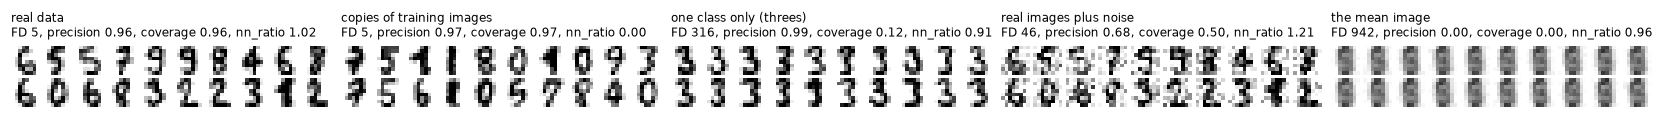

In [2]:
ROWS = {}                                                       # every scored set of samples, by name

def score(x, name, nfe=1, keep=True, **extra):
    row = card.evaluate(x, name, nfe=nfe, **extra); card.rows.pop()
    row["classes"] = int((G.class_shares(judge, x) >= 0.02).sum()); row["contrast"] = G.contrast(x)
    if keep:
        ROWS[name] = row
    return row

COLS = ["fd", "precision", "coverage", "nn_ratio", "classes", "contrast", "nfe"]
def table(names):
    return pd.DataFrame([ROWS[n] for n in names]).set_index("model")[COLS].round({"fd": 1, "precision": 2, "coverage": 2, "nn_ratio": 2, "contrast": 3})

g = torch.Generator().manual_seed(0)
real = card.real_baseline(); card.rows.pop()
real.update(classes=int((G.class_shares(judge, Xte) >= 0.02).sum()), contrast=G.contrast(Xte)); ROWS["real data"] = real
known = {"real data": Xte,
         "copies of training images": Xtr[torch.randperm(len(Xtr), generator=g)[:N]],
         "one class only (threes)": Xtr[ytr == 3].repeat(3, 1)[:N],
         "real images plus noise": (Xte + 0.5 * torch.randn(Xte.shape, generator=g)).clamp(-1, 1),
         "the mean image": Xtr.mean(0, keepdim=True).repeat(N, 1) + 0.05 * torch.randn(N, 64, generator=g)}
for name, x in known.items():
    if name != "real data":
        score(x, name, nfe=0)
display(table(list(known)))

fig, axes = plt.subplots(1, 5, figsize=(15, 2.4))
for ax, (name, x) in zip(axes, known.items()):
    r = ROWS[name]
    images.show_grid(x[:20], nrow=10, ax=ax)
    ax.set_title(f"{name}\nFD {r['fd']:.0f}, precision {r['precision']:.2f}, coverage {r['coverage']:.2f}, nn_ratio {r['nn_ratio']:.2f}", fontsize=8)
plt.show()

**Reading the table.** Each flawed set is caught by a different column.

* **Copies of training images** score as well as real data on FD, precision and coverage (4.9, 0.97, 0.97). Only
  nn_ratio shows the problem: 0.00, because every sample has a training image at distance zero. A model that
  memorised its training set would look perfect on the first three scores.
* **One class only** has the highest precision in the table (0.99): every sample is a real three. Coverage is 0.12,
  and one class of ten receives samples. Precision cannot see missing diversity.
* **Real images plus noise** lose precision (0.68) and coverage (0.50). The contrast is above the data's (0.580
  against 0.479).
* **The mean image** fails everything, and its contrast (0.265) is about half the data's. This is what complete blur
  looks like in the numbers.

FD reacts in every case except the first (316, 46 and 942, against 5 for real data), but it does not say *which*
failure occurred. So every model below is reported on all the columns.

All scores use 359 samples and the 359 held-out images. Where we train a model three times, the spread between the
three runs shows how large a difference has to be before it means anything.

## 2. An autoencoder compresses, and cannot generate

The simplest way to learn about images without labels is to compress them. An **autoencoder** has an encoder that
maps an image $x$ (64 numbers) to a short code $z$ (8 numbers here) and a decoder that maps the code back. It is
trained to reproduce its input:

$$\mathcal{L}_{\text{AE}} = \lVert x - \text{dec}(\text{enc}(x)) \rVert^2 .$$

The decoder is a function from codes to images, so it looks like a generator: choose a code, decode it. The
question is which code to choose. Nothing in the loss says where the codes of real images lie.

reconstruction error on held-out images: 2.73  (squared error summed over 64 pixels)
standard deviation of the codes, per dimension: [2.8 2.9 3.  3.2 3.  3.2 2.8 2.9]


,fd,precision,coverage,nn_ratio,classes,contrast,nfe
model,,,,,,,
real data,5.4,0.96,0.96,1.02,10,0.479,0
"autoencoder, codes from N(0, 1)",179.6,0.54,0.18,0.99,7,0.395,1


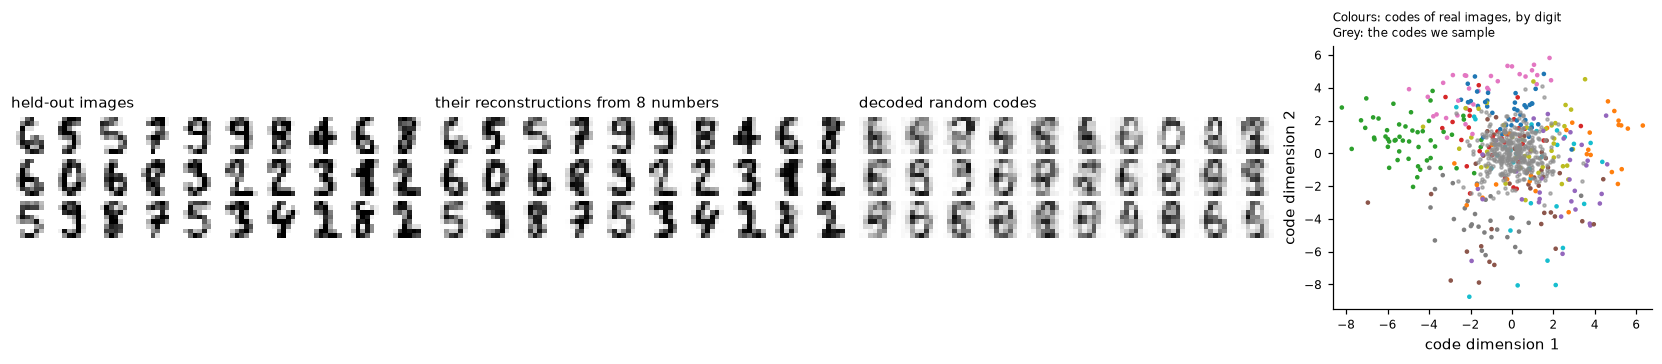

In [3]:
set_seed(0); ae = G.VAE(z_dim=8)
G.train_vae(ae, Xtr, steps=2000, beta=0.0, deterministic=True)        # KL weight 0 and no noise: a plain autoencoder
with torch.no_grad():
    ae_rec, ae_codes, _ = ae(Xte, deterministic=True)
ae_samples = ae.sample(N)                                              # decode codes drawn from a standard normal
r = score(ae_samples, "autoencoder, codes from N(0, 1)")
print(f"reconstruction error on held-out images: {float(((Xte - ae_rec) ** 2).sum(-1).mean()):.2f}  (squared error summed over 64 pixels)")
print(f"standard deviation of the codes, per dimension: {np.round(ae_codes.std(0).numpy(), 1)}")
display(table(["real data", "autoencoder, codes from N(0, 1)"]))

fig = plt.figure(figsize=(15, 3.2))
gs = fig.add_gridspec(1, 4, width_ratios=[1.3, 1.3, 1.3, 1])
for k, (x, title) in enumerate([(Xte[:30], "held-out images"), (ae_rec[:30], "their reconstructions from 8 numbers"), (ae_samples[:30], "decoded random codes")]):
    images.show_grid(x, nrow=10, ax=fig.add_subplot(gs[k]), title=title)
ax = fig.add_subplot(gs[3])
zs = torch.randn(N, 2, generator=torch.Generator().manual_seed(0))
ax.scatter(ae_codes[:, 0], ae_codes[:, 1], s=4, c=yte, cmap="tab10")
ax.scatter(zs[:, 0], zs[:, 1], s=4, color=viz.GREY, alpha=0.6)
ax.set_xlabel("code dimension 1"); ax.set_ylabel("code dimension 2"); ax.set_title("Colours: codes of real images, by digit\nGrey: the codes we sample", fontsize=8)
plt.show()

**What happened.** The autoencoder does its job. Reconstructions from 8 numbers have a squared error of 2.73 and
look like the originals. Decoding random codes fails: FD 180 against 5 for real data, precision 0.54, coverage 0.18,
and only 7 of the 10 digits receive at least 2% of the samples.

The scatter plot shows why. The codes of real images (colours) are spread over a region several times wider than the
standard normal we sampled from (grey): their standard deviation is about 3 in every dimension. They are also
grouped by digit. Codes drawn from the grey cloud cover only the centre of that region, and what the decoder
produces there does not look like the data.

Two things are missing: a known distribution to draw codes from, and a decoder that behaves sensibly between the
codes of real images.

## 3. The variational autoencoder

The variational autoencoder ([Kingma & Welling, 2013](https://arxiv.org/abs/1312.6114)) changes two things so that the decoder can be sampled.

1. The encoder outputs a **distribution** over codes for each image, a Gaussian $q(z \mid x) = \mathcal{N}(\mu(x),
   \sigma^2(x))$, and the decoder is trained on a code drawn from it. Neighbouring codes must then decode to similar
   images.
2. A penalty pulls every $q(z \mid x)$ towards a fixed **prior** $p(z) = \mathcal{N}(0, I)$. After training, codes
   drawn from the prior should land where the decoder was trained.

The loss is the negative of the *evidence lower bound* (ELBO), a lower bound on $\log p(x)$:

$$\mathcal{L}_{\text{VAE}} = \underbrace{\mathbb{E}_{z \sim q(z \mid x)} \lVert x - \text{dec}(z) \rVert^2}_{\text{reconstruction}}
\;+\; \beta \,\underbrace{\text{KL}\big(q(z \mid x)\,\Vert\,\mathcal{N}(0, I)\big)}_{\text{information the code carries about } x}.$$

For two Gaussians the KL term has a closed form, summed over the code dimensions:
$\tfrac12 \sum_j \big(\mu_j^2 + \sigma_j^2 - 1 - \log \sigma_j^2\big)$. It is zero for a dimension only when
$\mu_j = 0, \sigma_j = 1$ for every image, which means that dimension says nothing about the image. The KL term is
therefore the *price of information*, and $\beta$ sets the price. (With squared error as the reconstruction term,
$\beta = 1$ corresponds to assuming pixel noise of variance one half, which is large for pixels in $[-1, 1]$. So the
value of $\beta$ has no absolute meaning; section 4 sweeps it.)

### Design choice: the reparameterisation trick

The reconstruction term is an average over random codes $z \sim q(z \mid x)$, and the encoder's parameters decide
the distribution being sampled from. A gradient cannot pass through "draw a sample". There are two ways around this.

* **Score-function estimator** (REINFORCE, used by policy gradients in the post-training series): sample $z$, and
  weight the gradient of $\log q(z)$ by the loss. It needs no derivative of the loss with respect to $z$.
* **Reparameterisation** ([Kingma & Welling, 2013](https://arxiv.org/abs/1312.6114)): write the sample as a deterministic function of the parameters and of
  noise that does not depend on them, $z = \mu + \sigma \epsilon$ with $\epsilon \sim \mathcal{N}(0, I)$. Now the
  gradient passes through $z$ into $\mu$ and $\sigma$.

Both are unbiased. They differ in variance. The next cell estimates one gradient, $\tfrac{d}{d\mu}\,
\mathbb{E}_{z \sim \mathcal{N}(\mu, 1)}[z^2] = 2\mu$, both ways.

true gradient 3.00
reparameterisation: mean 3.00, standard deviation of one sample 2.00
score function:     mean 2.99, standard deviation of one sample 7.21


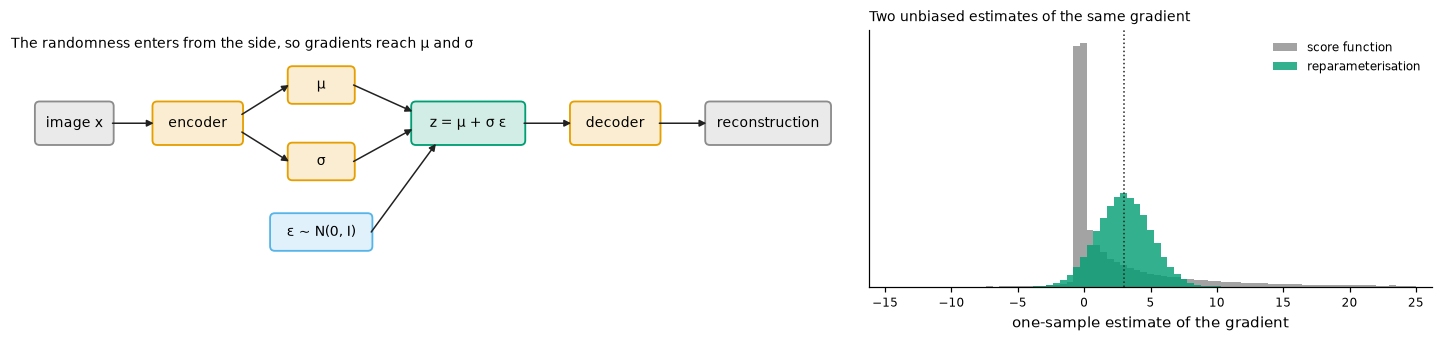

In [4]:
torch.manual_seed(0)
mu = 1.5
eps = torch.randn(100_000); z = mu + eps
reparam = 2 * z                                   # d/dmu of (mu + eps)^2
score_fn = z ** 2 * (z - mu)                      # loss * d/dmu log N(z; mu, 1)
print(f"true gradient {2 * mu:.2f}")
print(f"reparameterisation: mean {reparam.mean():.2f}, standard deviation of one sample {reparam.std():.2f}")
print(f"score function:     mean {score_fn.mean():.2f}, standard deviation of one sample {score_fn.std():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax = axes[0]
viz.diagram(ax, [(0, 1.2, 1.3, 0.7, "image x", viz.GREY), (2.0, 1.2, 1.5, 0.7, "encoder", viz.ORANGE), (4.3, 1.9, 1.1, 0.6, "μ", viz.ORANGE), (4.3, 0.6, 1.1, 0.6, "σ", viz.ORANGE),
                  (4.0, -0.6, 1.7, 0.6, "ε ~ N(0, I)", viz.SKY), (6.4, 1.2, 1.9, 0.7, "z = μ + σ ε", viz.GREEN), (9.1, 1.2, 1.5, 0.7, "decoder", viz.ORANGE), (11.4, 1.2, 2.1, 0.7, "reconstruction", viz.GREY)],
            [(1.3, 1.55, 2.0, 1.55), (3.5, 1.7, 4.3, 2.2), (3.5, 1.4, 4.3, 0.9), (5.4, 2.2, 6.4, 1.75), (5.4, 0.9, 6.4, 1.45), (5.7, -0.3, 6.8, 1.2), (8.3, 1.55, 9.1, 1.55), (10.6, 1.55, 11.4, 1.55)])
ax.set_title("The randomness enters from the side, so gradients reach μ and σ", fontsize=9)
ax = axes[1]
bins = np.linspace(-15, 25, 80)
ax.hist(score_fn.numpy(), bins=bins, color=viz.GREY, alpha=0.8, density=True, label="score function")
ax.hist(reparam.numpy(), bins=bins, color=viz.GREEN, alpha=0.8, density=True, label="reparameterisation")
ax.axvline(2 * mu, color=viz.BLACK, ls=":", lw=1); ax.set_xlabel("one-sample estimate of the gradient"); ax.set_yticks([])
ax.set_title("Two unbiased estimates of the same gradient", fontsize=9); ax.legend(fontsize=8, loc="upper right")
plt.show()

Both estimates average to the true gradient, 3.00 (the score-function estimate gives 2.99 over 100,000 samples).
One sample of the reparameterised estimate has a standard deviation of 2.00. One sample of the score-function
estimate has 7.21, a variance about 13 times larger. Training uses one sample per image, so this is the noise in
every gradient step.

Reparameterisation is why a VAE can be trained with ordinary backpropagation. Its condition is that $z$ is a
differentiable function of the noise. It does not apply directly to discrete codes, which is why the quantised
autoencoder of notebook 08 needs a different device.

### Training a VAE

The whole model is a few lines (`prelib/generative.py`): the encoder returns $\mu$ and $\log \sigma^2$, the sample is
`mu + randn_like(mu) * exp(0.5 * logvar)`, and the loss is the squared error plus $\beta$ times the closed-form KL.

{'reconstruction error': 4.68, 'KL (nats)': 4.96, 'latent dimensions in use': 5}
contrast: held-out images 0.479, reconstructions 0.427, samples 0.406


,fd,precision,coverage,nn_ratio,classes,contrast,nfe
model,,,,,,,
real data,5.4,0.96,0.96,1.02,10,0.479,0
"autoencoder, codes from N(0, 1)",179.6,0.54,0.18,0.99,7,0.395,1
"VAE, KL weight 1, seed 0",83.0,0.74,0.68,0.95,10,0.406,1


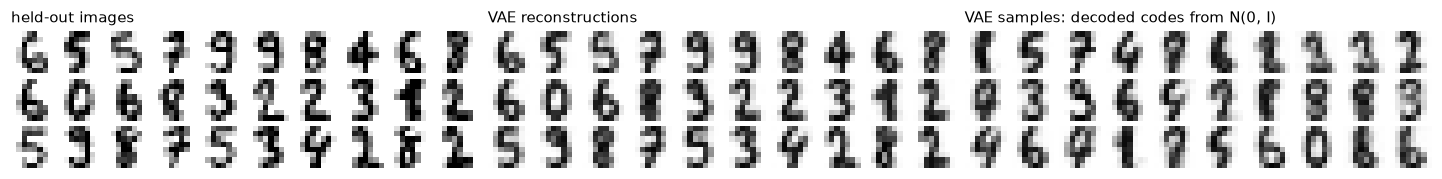

In [5]:
set_seed(0); vae = G.VAE(z_dim=8)
G.train_vae(vae, Xtr, steps=2000, beta=1.0)
with torch.no_grad():
    vae_rec = vae(Xte, deterministic=True)[0]
vae_samples = vae.sample(N)
score(vae_samples, "VAE, KL weight 1, seed 0")
print({k: round(v, 2) for k, v in G.vae_report(vae, Xte).items()})
print(f"contrast: held-out images {G.contrast(Xte):.3f}, reconstructions {G.contrast(vae_rec):.3f}, samples {G.contrast(vae_samples):.3f}")
display(table(["real data", "autoencoder, codes from N(0, 1)", "VAE, KL weight 1, seed 0"]))
fig, axes = plt.subplots(1, 3, figsize=(13, 2.6))
for ax, (x, title) in zip(axes, [(Xte[:30], "held-out images"), (vae_rec[:30], "VAE reconstructions"), (vae_samples[:30], "VAE samples: decoded codes from N(0, I)")]):
    images.show_grid(x, nrow=10, ax=ax, title=title)
plt.show()

**What happened.** Sampling now works. FD falls from 180 to 83 and coverage rises from 0.18 to 0.68, with all ten
digits present. The cost is in the middle panel and in the printed line. The reconstruction error is 4.68, against
2.73 for the autoencoder, and only 5 of the 8 code dimensions are in use. The images are also softer: the contrast
of the samples is 0.406 and of the reconstructions 0.427, against 0.479 for real images. And an FD of 83 is still
far from 5.

### Seeing the latent space

With a code of only two numbers the whole latent space can be drawn. The next cell trains a VAE with $z \in
\mathbb{R}^2$ and records it during training. The animation shows, on the left, where the encoder places the
held-out images (one dot per image, coloured by digit) and, on the right, what the decoder produces at each point of
a grid over the same plane.

VAE with a 2-number code: reconstruction error 7.24, samples FD 92, precision 0.86, coverage 0.47
saved figures/nb06_latent_plane.gif  (20 frames, 876 kB)


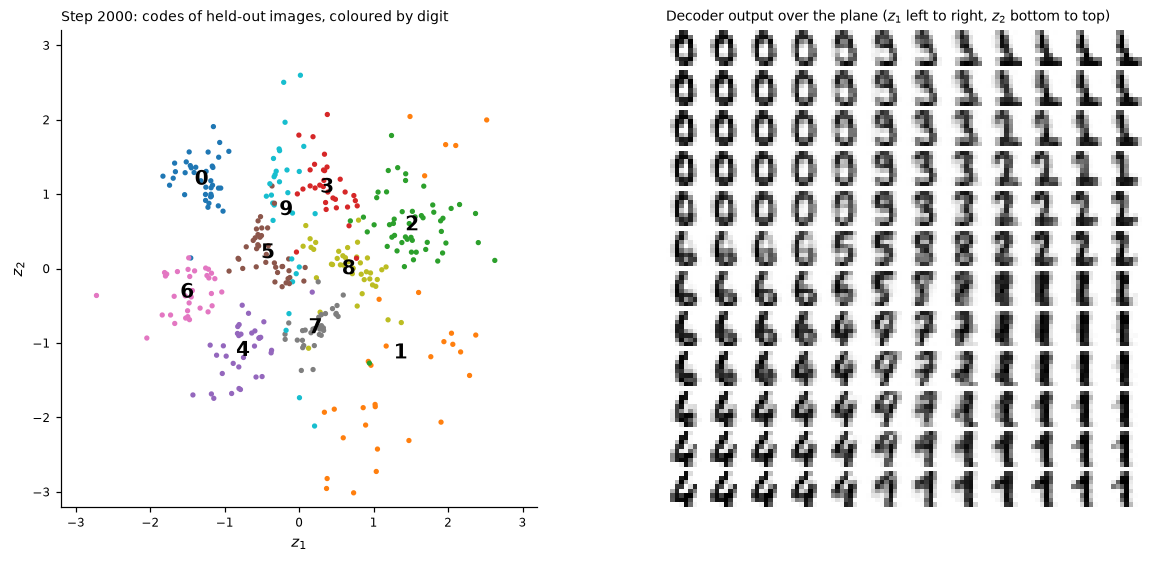

In [6]:
set_seed(0); vae2 = G.VAE(z_dim=2)
grid_1d = torch.linspace(-2.5, 2.5, 12)
plane = torch.stack(torch.meshgrid(grid_1d, grid_1d, indexing="xy"), -1).reshape(-1, 2)          # 144 points of the latent plane
plane[:, 1] = -plane[:, 1]                                                                       # so that the top row of the picture is z2 = +2.5
snaps = []
def record(step, model):
    with torch.no_grad():
        snaps.append((step, model.encode(Xte)[0].clone(), model.dec(plane).clone()))
G.train_vae(vae2, Xtr, steps=2000, beta=1.0, callback=record, at=(10, 20, 40, 70, 100, 150, 200, 300, 400, 600, 800, 1000, 1300, 1600, 2000))
r2 = score(vae2.sample(N), "VAE with a 2-number code", keep=False)
print(f"VAE with a 2-number code: reconstruction error {G.vae_report(vae2, Xte)['reconstruction error']:.2f}, samples FD {r2['fd']:.0f}, precision {r2['precision']:.2f}, coverage {r2['coverage']:.2f}")

def draw_plane(axes, step, codes, decoded, mark=None):
    axes[0].scatter(codes[:, 0], codes[:, 1], s=6, c=yte, cmap="tab10", vmin=0, vmax=9)
    axes[0].set_xlim(-3.2, 3.2); axes[0].set_ylim(-3.2, 3.2); axes[0].set_aspect("equal")
    axes[0].set_xlabel("$z_1$"); axes[0].set_ylabel("$z_2$"); axes[0].set_title(f"Step {step}: codes of held-out images, coloured by digit", fontsize=9)
    images.show_grid(decoded, nrow=12, ax=axes[1]); axes[1].set_title("Decoder output over the plane ($z_1$ left to right, $z_2$ bottom to top)", fontsize=9)
    if mark is not None:
        axes[0].plot(*mark, marker="x", color=viz.BLACK, ms=12, mew=2.5)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
def frame(k):
    for ax in axes:
        ax.clear()
    draw_plane(axes, *snaps[k])
viz.save_gif(fig, frame, list(range(len(snaps))) + [len(snaps) - 1] * 4, "nb06_latent_plane.gif", fps=3)
fig, axes = plt.subplots(1, 2, figsize=(11, 5)); draw_plane(axes, *snaps[-1])
for d in range(10):                                                                              # label each cluster with its digit
    c = snaps[-1][1][yte == d].mean(0); axes[0].text(c[0], c[1], str(d), fontsize=13, fontweight="bold", ha="center", va="center")
plt.show()

![A two-dimensional VAE latent space organising itself during training: codes of held-out digits on the left, decoded images over the plane on the right](figures/nb06_latent_plane.gif)

**What to look for.** At step 0 every image is encoded to almost the same point, and the decoder produces the same
grey image everywhere. By step 40 the codes have spread out and are already grouped by digit, although the model is
never told which digit an image shows. By step 150 most digits have their own region. At the end the decoder output
changes smoothly across the plane: follow any row of the right-hand panel. Between two regions the decoder produces
a blend of two digits. Codes drawn from the prior land in those places too, which is one source of poor samples.

A code of two numbers is for drawing pictures. The line printed above the figure gives its scores, to compare with
the 8-number model used in the rest of the notebook.

### Try it: walk through the latent plane

Static preview at the default settings {'z1': 0.0, 'z2': 0.0}. Run the notebook to get the controls.


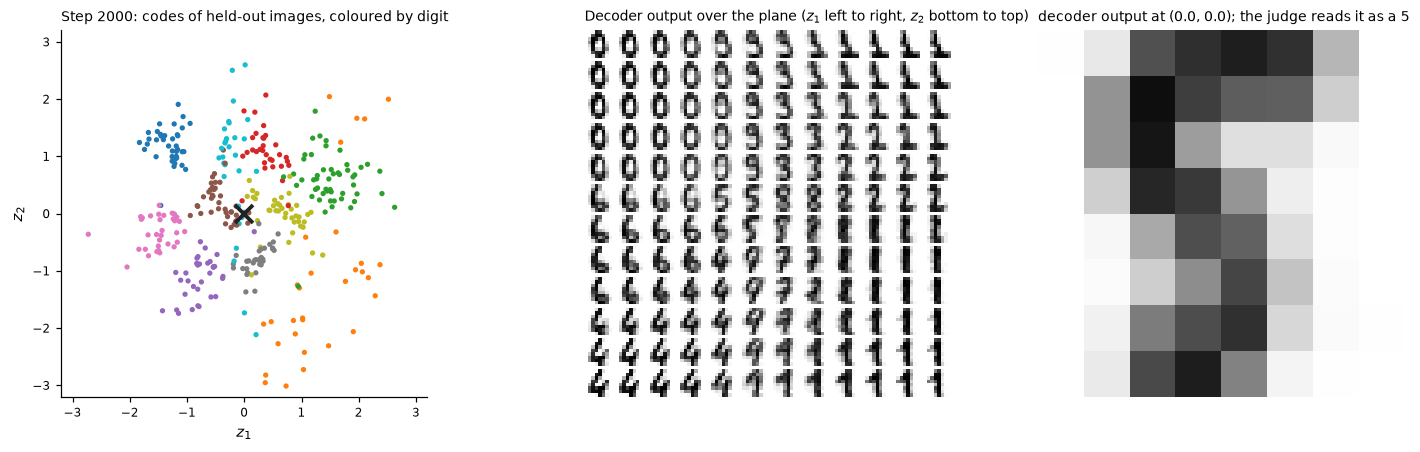

In [7]:
def latent_explorer(z1=0.0, z2=0.0):
    with torch.no_grad():
        img = vae2.dec(torch.tensor([[z1, z2]]))
        label = int(judge(img).argmax(1))
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1.1, 1.1, 0.8]))
    draw_plane(axes[:2], 2000, snaps[-1][1], snaps[-1][2], mark=(z1, z2))
    axes[2].imshow(img.view(8, 8), cmap="gray_r", vmin=-1, vmax=1); axes[2].axis("off")
    axes[2].set_title(f"decoder output at ({z1:.1f}, {z2:.1f}); the judge reads it as a {label}", fontsize=9)
    plt.show()
viz.explore(latent_explorer, z1=(-2.5, 2.5, 0.1, 0.0), z2=(-2.5, 2.5, 0.1, 0.0))

## 4. The price of information: sweeping the KL weight

The two terms of the VAE loss pull in opposite directions. A code that carries more information about the image
reconstructs it better and costs more KL. The weight $\beta$ sets the exchange rate. We train the 8-number VAE at
seven values of $\beta$ and measure, for each: the reconstruction error, the KL, the number of code dimensions *in
use* (KL above 0.01 nats; the others have been switched off), and the scores of its samples.

Mean of three seeds for each KL weight:


,reconstruction error,KL (nats),"dimensions in use, by seed",fd,"fd, lowest to highest",precision,coverage,contrast
KL weight,,,,,,,,
0.01,2.60,28.35,8 8 8,95.6,89 to 104,0.68,0.41,0.409
0.03,2.56,21.72,8 8 8,59.7,56 to 67,0.78,0.57,0.423
0.10,2.55,15.70,8 8 8,50.8,45 to 58,0.79,0.65,0.434
0.30,2.94,9.92,7 7 8,52.3,46 to 56,0.80,0.73,0.431
1.00,4.71,4.94,5 5 5,79.6,76 to 83,0.76,0.69,0.406
3.00,9.47,1.57,3 3 3,286.0,260 to 303,0.30,0.18,0.341
10.00,18.79,0.00,0 0 0,976.2,965 to 982,0.00,0.00,0.249


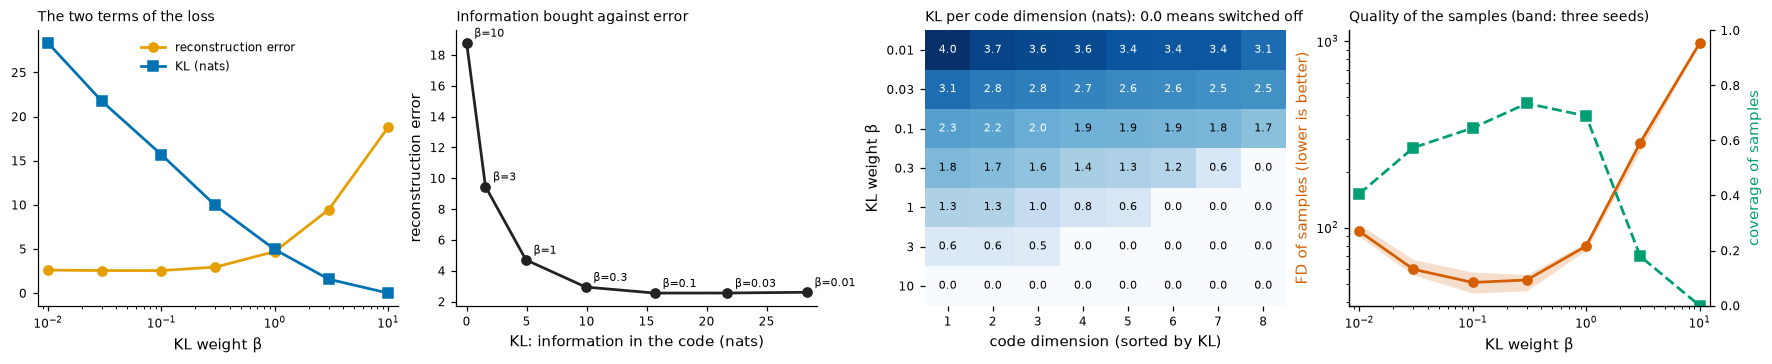

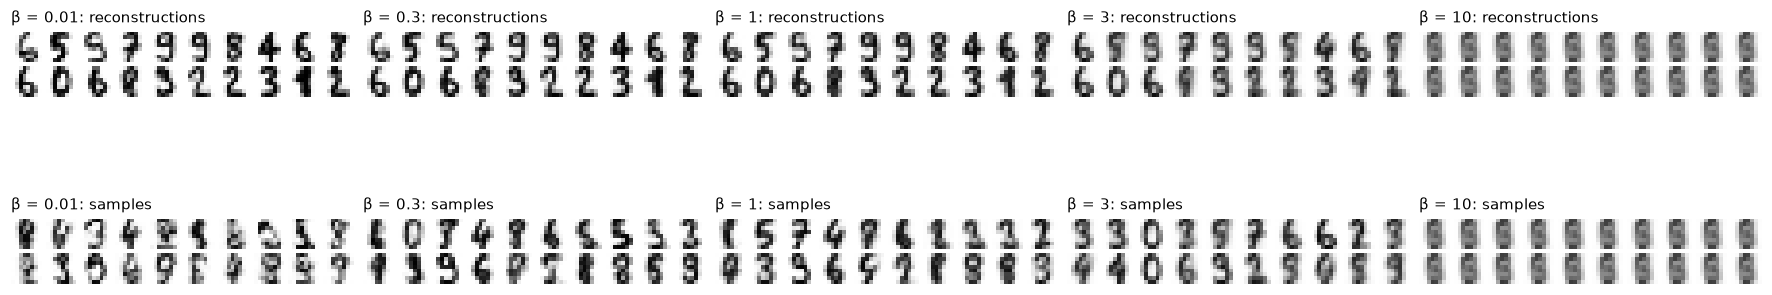

In [8]:
BETAS = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
sweep, runs = {}, []
for beta in BETAS:
    for seed in (0, 1, 2):
        set_seed(seed); m = G.VAE(z_dim=8); G.train_vae(m, Xtr, steps=2000, beta=beta, seed=seed)
        s = m.sample(N); r = score(s, f"VAE, KL weight {beta:g}, seed {seed}")
        runs.append({"KL weight": beta, "seed": seed, **G.vae_report(m, Xte), **{k: r[k] for k in ("fd", "precision", "coverage", "contrast")}})
        if seed == 0:                                               # the first model of each setting is kept for the pictures
            with torch.no_grad():
                rec, mu, logvar = m(Xte, deterministic=True)
            sweep[beta] = dict(model=m, rec=rec, samples=s, kl_dims=G.kl_per_dim(mu, logvar).numpy(), **runs[-1])
runs = pd.DataFrame(runs)
by = runs.groupby("KL weight")
sweep_table = by.mean().drop(columns=["seed", "latent dimensions in use"])                 # mean of three seeds
sweep_table.insert(2, "dimensions in use, by seed", by["latent dimensions in use"].agg(lambda v: " ".join(str(int(x)) for x in v)))
sweep_table.insert(4, "fd, lowest to highest", by["fd"].agg(lambda v: f"{v.min():.0f} to {v.max():.0f}"))
print("Mean of three seeds for each KL weight:")
display(sweep_table.round({"reconstruction error": 2, "KL (nats)": 2, "fd": 1, "precision": 2, "coverage": 2, "contrast": 3}))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
ax = axes[0]
ax.plot(BETAS, sweep_table["reconstruction error"], "o-", color=viz.ORANGE, label="reconstruction error")
ax.plot(BETAS, sweep_table["KL (nats)"], "s-", color=viz.BLUE, label="KL (nats)")
ax.set_xscale("log"); ax.set_xlabel("KL weight β"); ax.set_title("The two terms of the loss", fontsize=9); ax.legend(fontsize=8, loc="upper center")
ax = axes[1]
ax.plot(sweep_table["KL (nats)"], sweep_table["reconstruction error"], "o-", color=viz.BLACK)
for b in BETAS:
    ax.annotate(f"β={b:g}", (sweep_table.loc[b, "KL (nats)"], sweep_table.loc[b, "reconstruction error"]), textcoords="offset points", xytext=(5, 4), fontsize=7)
ax.set_xlabel("KL: information in the code (nats)"); ax.set_ylabel("reconstruction error"); ax.set_title("Information bought against error", fontsize=9)
ax = axes[2]
viz.heat(ax, np.stack([np.sort(sweep[b]["kl_dims"])[::-1] for b in BETAS]), xlabels=[str(i + 1) for i in range(8)], ylabels=[f"{b:g}" for b in BETAS], annotate=True, fmt="{:.1f}", cmap="Blues")
ax.set_xlabel("code dimension (sorted by KL)"); ax.set_ylabel("KL weight β"); ax.set_title("KL per code dimension (nats): 0.0 means switched off", fontsize=9)
ax = axes[3]
ax.plot(BETAS, sweep_table["fd"], "o-", color=viz.VERMILION); ax.fill_between(BETAS, by["fd"].min(), by["fd"].max(), color=viz.VERMILION, alpha=0.2, lw=0); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("KL weight β"); ax.set_ylabel("FD of samples (lower is better)", color=viz.VERMILION)
ax2 = ax.twinx(); ax2.plot(BETAS, sweep_table["coverage"], "s--", color=viz.GREEN); ax2.set_ylabel("coverage of samples", color=viz.GREEN); ax2.set_ylim(0, 1); ax2.spines["right"].set_visible(True)
ax.set_title("Quality of the samples (band: three seeds)", fontsize=9)
plt.show()

show = [0.01, 0.3, 1.0, 3.0, 10.0]
fig, axes = plt.subplots(2, len(show), figsize=(16, 3.4))
for j, b in enumerate(show):
    images.show_grid(sweep[b]["rec"][:20], nrow=10, ax=axes[0, j], title=f"β = {b:g}: reconstructions")
    images.show_grid(sweep[b]["samples"][:20], nrow=10, ax=axes[1, j], title=f"β = {b:g}: samples")
plt.show()

**Reading the sweep.** All numbers are means of three seeds, and the table gives the range of FD.

* **Low price, $\beta \le 0.1$.** The code carries 16 to 28 nats and all 8 dimensions are in use. Reconstruction is
  as good as the plain autoencoder's (2.55 to 2.60, against 2.73). But the samples get worse as $\beta$ falls: FD 51
  at 0.1, 60 at 0.03 and 96 at 0.01, with coverage falling from 0.65 to 0.41. With almost no pull towards the prior,
  the codes drift away from $\mathcal{N}(0, I)$ and we are back at the autoencoder's problem.
* **The useful range, $\beta$ from 0.1 to 0.3.** FD is lowest here (51 and 52). The ranges over seeds, 45 to 58 and
  46 to 56, overlap, so the two settings cannot be told apart on FD. Coverage is highest at 0.3 (0.73).
* **High price, $\beta \ge 1$.** Dimensions are switched off: 5 of 8 remain at $\beta = 1$ and 3 at $\beta = 3$. From
  $\beta = 0.3$ to 1 to 3 the reconstruction error rises from 2.94 to 4.71 to 9.47, the contrast of the samples
  falls from 0.431 to 0.406 to 0.341, and FD rises from 52 to 80 to 286.
* **Posterior collapse, $\beta = 10$.** Every dimension is switched off, in all three seeds. The KL is 0.00: the
  encoder outputs the prior for every image, the code carries nothing, and the decoder produces the single image
  that minimises squared error with no information, the mean. Its FD (976) is close to that of "the mean image" in
  section 1 (942).

The third panel shows *how* the code shrinks. The model does not use all 8 dimensions a little less. It keeps some
and switches the others off completely.

Even the best setting is poor by the standard of section 1: FD about 50 against 5 for real data, and a contrast of
0.43 against 0.479. No value of $\beta$ gives sharp samples.

### Try it: choose the KL weight

Static preview at the default settings {'kl_weight': '1'}. Run the notebook to get the controls.


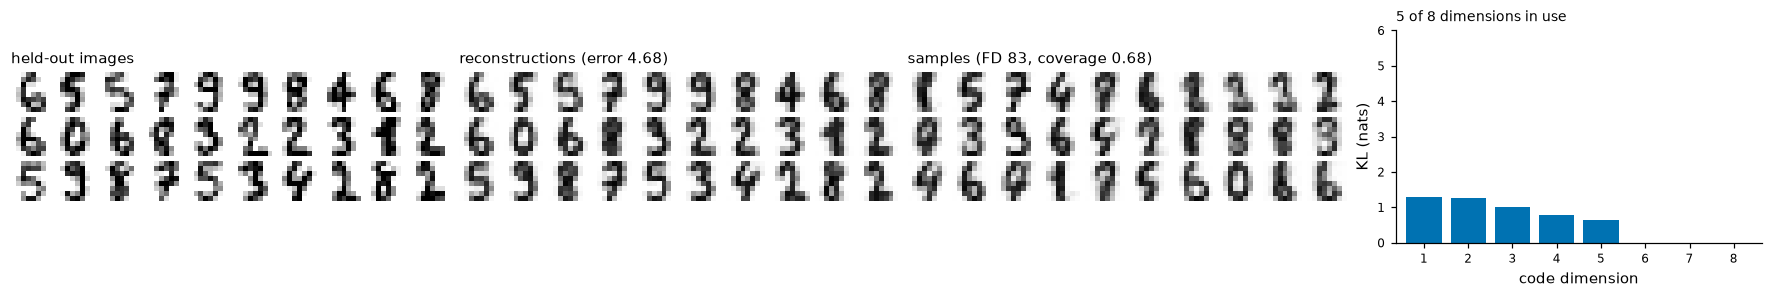

In [9]:
def beta_explorer(kl_weight="1"):
    b = float(kl_weight); r = sweep[b]
    fig, axes = plt.subplots(1, 4, figsize=(16, 2.6), gridspec_kw=dict(width_ratios=[1.2, 1.2, 1.2, 1]))
    images.show_grid(Xte[:30], nrow=10, ax=axes[0], title="held-out images")
    images.show_grid(r["rec"][:30], nrow=10, ax=axes[1], title=f"reconstructions (error {r['reconstruction error']:.2f})")
    images.show_grid(r["samples"][:30], nrow=10, ax=axes[2], title=f"samples (FD {r['fd']:.0f}, coverage {r['coverage']:.2f})")
    axes[3].bar(range(1, 9), np.sort(r["kl_dims"])[::-1], color=viz.BLUE); axes[3].set_ylim(0, 6); axes[3].set_xlabel("code dimension"); axes[3].set_ylabel("KL (nats)")
    axes[3].set_title(f"{r['latent dimensions in use']} of 8 dimensions in use", fontsize=9)
    plt.show()
viz.explore(beta_explorer, kl_weight=["1", "0.01", "0.03", "0.1", "0.3", "3", "10"])

### Why VAE samples are blurred

The blur has a simple cause. Squared error is minimised by the *mean* of all images consistent with the code. If a
code does not say exactly where a stroke is, the best answer under squared error is an average of the possible
strokes: a grey smear. The less information the code carries (larger $\beta$), the more is averaged.

This is the failure that motivated everything after it. One response was to make the code so informative that the
decoder has almost nothing to average, and to give up on sampling the code from a simple prior: a second model
learns the distribution of codes instead. That is the design of VQ-VAE ([Oord et al., 2017](https://arxiv.org/abs/1711.00937)) and of latent diffusion
([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)), which notebook 08 builds. The other response was to replace squared error with a loss that
punishes blur. That is the next section.

## 5. Generative adversarial networks

A GAN ([Goodfellow et al., 2014](https://arxiv.org/abs/1406.2661)) has no encoder and no reconstruction loss. A **generator** $G$ maps noise $z \sim
\mathcal{N}(0, I)$ to an image. A **discriminator** $D$ is a classifier trained to tell real images from generated
ones. The generator is trained to make the discriminator wrong:

$$\min_G \max_D \;\; \mathbb{E}_{x \sim \text{data}} \log D(x) \;+\; \mathbb{E}_{z} \log\big(1 - D(G(z))\big).$$

The discriminator is a *learned loss*. A blurred image is easy to tell from a real one, so blur is punished without
anyone writing down what blur is.

In practice the two networks take turns, one gradient step each. The generator uses the **non-saturating** form of
its loss, maximise $\log D(G(z))$ instead of minimising $\log(1 - D(G(z)))$, as the original paper recommends: early
in training the discriminator rejects every sample with confidence, and the original form then has almost no
gradient.

We train the same GAN three times with different random seeds, and measure the samples every 250 steps.

,fd,precision,coverage,nn_ratio,classes,contrast,nfe
model,,,,,,,
"GAN, seed 0",53.0,0.63,0.27,0.99,9,0.490,1
"GAN, seed 1",60.7,0.75,0.39,1.01,10,0.498,1
"GAN, seed 2",56.2,0.62,0.31,1.01,10,0.524,1


FD every 500 steps:


step,250,750,1250,1750,2250,2750
seed 0,717.0,159.0,111.0,104.0,70.0,67.0
seed 1,624.0,137.0,90.0,54.0,46.0,43.0
seed 2,651.0,179.0,157.0,64.0,52.0,29.0


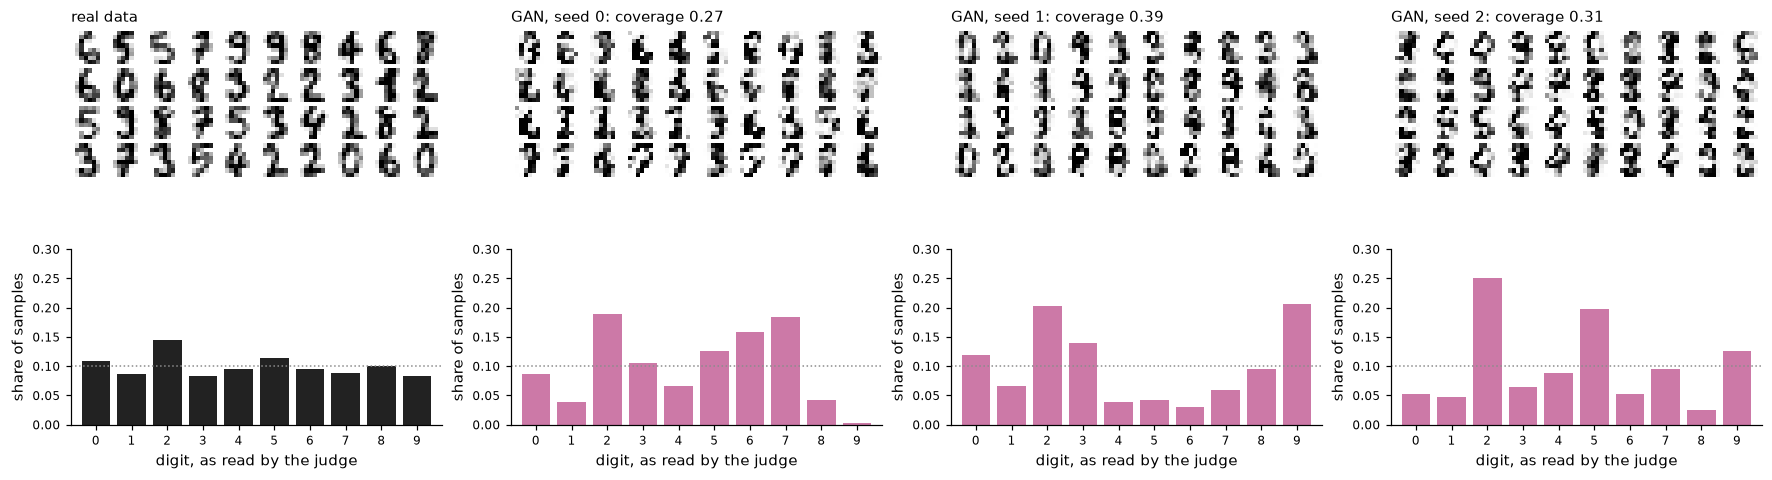

In [10]:
def gan_run(loss, seed, steps=3000, spectral=False, **kw):
    set_seed(seed)
    gen, disc, track = G.Generator(), G.Critic(spectral=spectral), []
    def measure(step, gen):
        r = score(gen.sample(N), "in training", keep=False)
        track.append(dict(step=step, fd=r["fd"], coverage=r["coverage"], classes=r["classes"]))
    t0 = time.time()
    log = np.array(G.train_gan(gen, disc, Xtr, steps=steps, loss=loss, seed=seed, callback=measure, every=250, **kw))
    track = pd.DataFrame(track).set_index("step")
    track["critic loss"] = [log[s - 250:s, 0].mean() for s in track.index]; track["generator loss"] = [log[s - 250:s, 1].mean() for s in track.index]
    return dict(gen=gen, track=track, seconds=time.time() - t0, samples=gen.sample(N))

gans = {seed: gan_run("gan", seed) for seed in range(3)}
for seed, r in gans.items():
    score(r["samples"], f"GAN, seed {seed}")
display(table([f"GAN, seed {s}" for s in gans]))
print("FD every 500 steps:")
display(pd.DataFrame({f"seed {s}": r["track"]["fd"] for s, r in gans.items()}).loc[::2].T.round(0))

fig, axes = plt.subplots(2, 4, figsize=(16, 4.6), gridspec_kw=dict(height_ratios=[1.5, 1]))
panels = [("real data", Xte)] + [(f"GAN, seed {s}", r["samples"]) for s, r in gans.items()]
for j, (name, x) in enumerate(panels):
    images.show_grid(x[:40], nrow=10, ax=axes[0, j], title=name if j == 0 else f"{name}: coverage {ROWS[name]['coverage']:.2f}")
    shares = G.class_shares(judge, x)
    axes[1, j].bar(range(10), shares, color=viz.BLACK if j == 0 else viz.PINK); axes[1, j].axhline(0.1, color=viz.GREY, ls=":", lw=1)
    axes[1, j].set_xticks(range(10)); axes[1, j].set_ylim(0, 0.3); axes[1, j].set_xlabel("digit, as read by the judge"); axes[1, j].set_ylabel("share of samples")
plt.show()

**What happened.** The samples have what the VAE's lacked: strokes are dark and edges are hard. The contrast is
0.49 to 0.52, at or above the 0.479 of real images, where the VAEs of section 4 gave 0.41 to 0.43. The discriminator
punished blur, as intended. Everything else is worse.

* **Coverage is low**: 0.27, 0.39 and 0.31, against about 0.7 for the VAE and 0.96 for real data. The bar charts
  show uneven shares of the ten digits, and seed 0 gives less than 2% of its samples to one digit.
* **Precision is low too**: 0.62 to 0.75. Many samples are sharp and are not digits. Sharp is not the same as
  good, and the usual summary "GANs give high-quality samples" does not describe this small GAN.
* **Training does not settle.** FD was measured every 250 steps. Seed 2 reached 29 at step 2,750 and ended at 56
  at step 3,000. Nothing in a GAN says when to stop; section 7 looks at its loss curves.

## 6. Mode dropping in two dimensions

The loss of diversity is easier to see where the whole distribution can be drawn. The standard test is a mixture of
eight narrow Gaussians on a circle. A generator with two inputs and two outputs has to learn to send noise to all
eight.

The generator is only ever asked to fool the *current* discriminator. If it puts all its samples on a few modes
that the discriminator currently accepts, its loss is low. Nothing in its loss rewards covering the rest. This is
**mode dropping** (also called mode collapse).

### Design choice: from the GAN loss to the Wasserstein loss with a gradient penalty

[Arjovsky et al., 2017](https://arxiv.org/abs/1701.07875) traced the instability to the loss itself. When the real and generated distributions do not
overlap, a perfect discriminator separates them completely and passes no useful gradient to the generator. They
proposed that the second network should estimate the **Wasserstein distance** between the two distributions (how far
probability mass has to be moved to turn one into the other), which varies smoothly even without overlap. The second
network is then called a *critic*: it outputs an unbounded score, and it must be 1-Lipschitz (its output may not
change faster than its input).

$$\min_G \max_{D \,\in\, \text{1-Lipschitz}} \;\; \mathbb{E}_{x \sim \text{data}} D(x) \;-\; \mathbb{E}_{z} D(G(z)).$$

[Gulrajani et al., 2017](https://arxiv.org/abs/1704.00028) enforced the constraint with a **gradient penalty**: on points between real and generated samples,
the norm of the critic's gradient is pushed towards one,
$\lambda \, \mathbb{E}_{\hat x}\big(\lVert \nabla_{\hat x} D(\hat x) \rVert - 1\big)^2$, and the critic takes five steps for
each generator step. [Miyato et al., 2018](https://arxiv.org/abs/1802.05957) enforced it instead by dividing each weight matrix of the critic by its largest
singular value (**spectral normalisation**), which costs no extra backward pass.

We train on the ring: the GAN loss at two learning rates, and the Wasserstein loss at two penalty weights $\lambda$.
For each run we count how many of the eight modes receive at least 2% of the samples, and what share of all samples
lies within 0.3 of a mode centre.

,step 500,step 1000,step 2000,step 3000,step 4000
"GAN loss, learning rate 0.0002","0 modes, 0.07 near","5 modes, 0.19 near","8 modes, 0.29 near","7 modes, 0.43 near","7 modes, 0.51 near"
"GAN loss, learning rate 0.001","8 modes, 0.38 near","8 modes, 0.52 near","5 modes, 0.71 near","4 modes, 0.80 near","4 modes, 0.83 near"
"GAN loss, learning rate 0.001, seed 1","7 modes, 0.31 near","8 modes, 0.51 near","7 modes, 0.68 near","5 modes, 0.75 near","4 modes, 0.79 near"
"GAN loss, learning rate 0.001, seed 2","8 modes, 0.41 near","7 modes, 0.55 near","5 modes, 0.70 near","6 modes, 0.76 near","4 modes, 0.80 near"
"Wasserstein + gradient penalty, λ = 1","0 modes, 0.05 near","0 modes, 0.08 near","8 modes, 0.25 near","8 modes, 0.34 near","8 modes, 0.36 near"
"Wasserstein + gradient penalty, λ = 10","1 modes, 0.06 near","0 modes, 0.05 near","0 modes, 0.06 near","3 modes, 0.17 near","4 modes, 0.16 near"


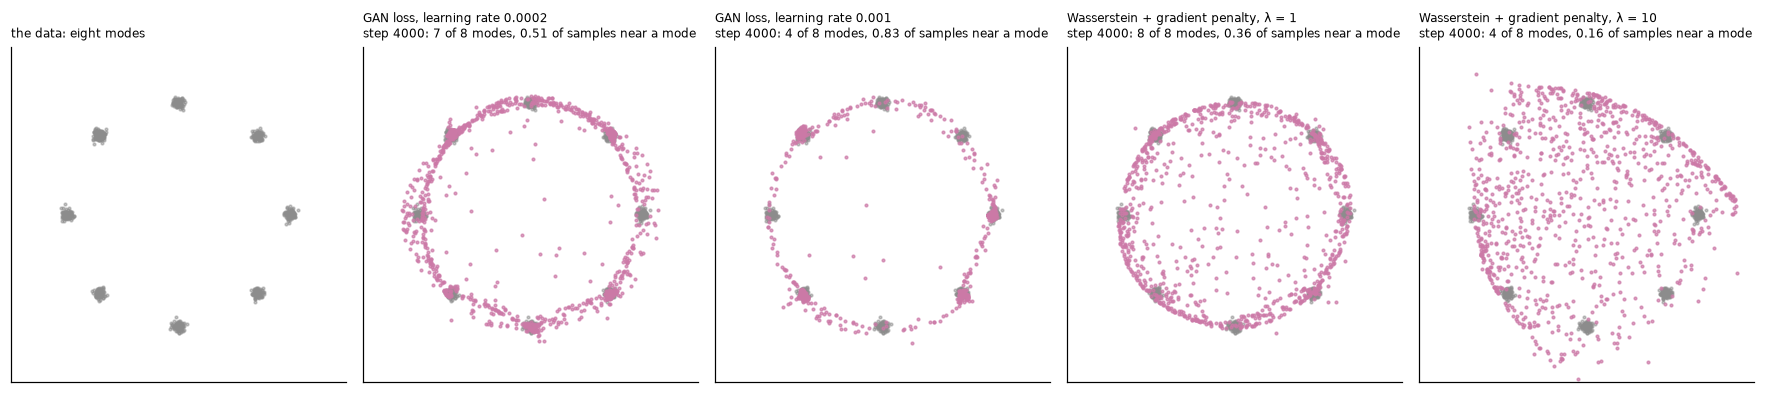

saved figures/nb06_ring.gif  (20 frames, 310 kB)


'figures/nb06_ring.gif'

In [11]:
ring = G.ring(4000)
def ring_run(loss, steps=4000, seed=0, **kw):
    set_seed(seed)
    gen, disc, shots = G.Generator(z_dim=2, hidden=64, x_dim=2, squash=False), G.Critic(hidden=64, x_dim=2), []
    G.train_gan(gen, disc, ring, steps=steps, loss=loss, seed=seed, callback=lambda s, g: shots.append((s, g.sample(1000))), every=250, **kw)
    return shots

ring_runs = {"GAN loss, learning rate 0.0002": ring_run("gan"),
             "GAN loss, learning rate 0.001": ring_run("gan", lr=1e-3),
             "GAN loss, learning rate 0.001, seed 1": ring_run("gan", lr=1e-3, seed=1),
             "GAN loss, learning rate 0.001, seed 2": ring_run("gan", lr=1e-3, seed=2),
             "Wasserstein + gradient penalty, λ = 1": ring_run("wgan-gp", gp=1.0),
             "Wasserstein + gradient penalty, λ = 10": ring_run("wgan-gp", gp=10.0)}
at = [500, 1000, 2000, 3000, 4000]
modes = pd.DataFrame({name: {f"step {s}": "{} modes, {:.2f} near".format(*G.ring_modes(x)) for s, x in shots if s in at} for name, shots in ring_runs.items()}).T
display(modes)

show = ["GAN loss, learning rate 0.0002", "GAN loss, learning rate 0.001", "Wasserstein + gradient penalty, λ = 1", "Wasserstein + gradient penalty, λ = 10"]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
def draw_ring(ax, x, title):
    ax.scatter(ring[:800, 0], ring[:800, 1], s=3, color=viz.GREY, alpha=0.5)
    if x is not None:
        ax.scatter(x[:, 0], x[:, 1], s=3, color=viz.PINK, alpha=0.7)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=8)
draw_ring(axes[0], None, "the data: eight modes")
for ax, name in zip(axes[1:], show):
    x = ring_runs[name][-1][1]; m, near = G.ring_modes(x)
    draw_ring(ax, x, f"{name}\nstep 4000: {m} of 8 modes, {near:.2f} of samples near a mode")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
pair = ["GAN loss, learning rate 0.001", "Wasserstein + gradient penalty, λ = 1"]
def frame(k):
    for ax, name in zip(axes, pair):
        ax.clear(); s, x = ring_runs[name][k]; m, near = G.ring_modes(x)
        draw_ring(ax, x, f"{name}\nstep {s}: {m} of 8 modes")
viz.save_gif(fig, frame, list(range(16)) + [15] * 4, "nb06_ring.gif", fps=3)

![Samples from two generators trained on a ring of eight Gaussians: with the GAN loss at a high learning rate modes are lost during training; with the Wasserstein loss all eight are kept](figures/nb06_ring.gif)

**What happened.**

* **GAN loss, learning rate 0.001.** All three seeds lose modes during training. Each covers 7 or 8 modes at step
  1,000 and ends on 4. As modes are lost the remaining ones become sharper: the share of samples near a mode rises
  to about 0.8. The animation shows it happening.
* **GAN loss, learning rate 0.0002** (the setting used on the digits). It ends with 7 of 8 modes. Half of the
  samples (0.51) are near a mode and most of the rest lie on the circle between modes. Mode dropping is not
  inevitable. Here it depended on the learning rate.
* **Wasserstein loss, $\lambda = 1$.** All 8 modes from step 2,000 on, and none is lost afterwards. It is slower
  (almost nothing near a mode at step 1,000) and its samples are the least concentrated: 0.36 near a mode at the
  end.
* **Wasserstein loss, $\lambda = 10$,** the value [Gulrajani et al., 2017](https://arxiv.org/abs/1704.00028) used for images. It has not converged after
  4,000 steps: 4 modes, and 0.16 of the samples near one. The authors' own code for this toy problem
  ([`gan_toy.py`](https://github.com/igul222/improved_wgan_training/blob/master/gan_toy.py)) sets $\lambda = 0.1$
  with the comment that a smaller value is faster for toy tasks. The right weight depends on the data.

On this problem the Wasserstein loss gave what it promised, coverage without collapse. The costs were five critic
steps per generator step and a penalty weight that had to be changed from its default. It did not give sharper
modes than the GAN loss.

A note on how these settings were chosen. We ran the default settings first (learning rate 0.0002 for the GAN loss,
$\lambda = 10$ for the gradient penalty). The GAN did not collapse and the Wasserstein run did not converge. The
learning rate of 0.001 and $\lambda = 1$ were chosen after seeing that. So the animation compares a GAN setting
picked because it shows mode dropping with a Wasserstein setting picked because it converges. The table has all
four, and it is the fairer summary.

## 7. The Wasserstein loss on the digits

Now the same comparison on the digits: three seeds of the Wasserstein loss with gradient penalty (the default
$\lambda = 10$ of [Gulrajani et al., 2017](https://arxiv.org/abs/1704.00028)) against the three GANs of section 5. We also train the GAN loss with a
spectrally normalised discriminator, twice.

,fd,precision,coverage,nn_ratio,classes,contrast,nfe
model,,,,,,,
"GAN, seed 0",53.0,0.63,0.27,0.99,9,0.490,1
"GAN, seed 1",60.7,0.75,0.39,1.01,10,0.498,1
"GAN, seed 2",56.2,0.62,0.31,1.01,10,0.524,1
"GAN + spectral normalisation, seed 0",35.8,0.59,0.40,1.00,10,0.513,1
"GAN + spectral normalisation, seed 1",31.9,0.71,0.37,0.98,10,0.495,1
"WGAN-GP, seed 0",13.8,0.72,0.57,0.99,10,0.481,1
"WGAN-GP, seed 1",9.6,0.58,0.41,0.99,10,0.486,1
"WGAN-GP, seed 2",16.8,0.72,0.47,1.00,10,0.467,1


share of the samples that the judge reads as each digit:


,0,1,2,3,4,5,6,7,8,9
real data,0.11,0.09,0.14,0.08,0.09,0.11,0.09,0.09,0.10,0.08
"GAN, seed 0",0.09,0.04,0.19,0.11,0.07,0.13,0.16,0.18,0.04,0.00
"GAN, seed 1",0.12,0.07,0.20,0.14,0.04,0.04,0.03,0.06,0.09,0.21
"GAN, seed 2",0.05,0.05,0.25,0.06,0.09,0.20,0.05,0.09,0.03,0.13
"WGAN-GP, seed 0",0.11,0.11,0.14,0.08,0.08,0.10,0.11,0.11,0.03,0.13
"WGAN-GP, seed 1",0.11,0.08,0.23,0.09,0.06,0.13,0.10,0.08,0.02,0.10
"WGAN-GP, seed 2",0.09,0.08,0.14,0.11,0.08,0.13,0.13,0.08,0.04,0.12


training time per run: GAN 5 s, WGAN-GP 21 s (five critic steps, each with a second backward pass, per generator step)
WGAN-GP, seed 0, every 500 steps: FD and the critic's estimate of the distance (minus the critic loss)


step,250,750,1250,1750,2250,2750
FD,1098.90,131.81,13.38,12.56,10.54,11.52
critic's distance estimate,3.61,1.95,0.93,0.90,0.91,0.87


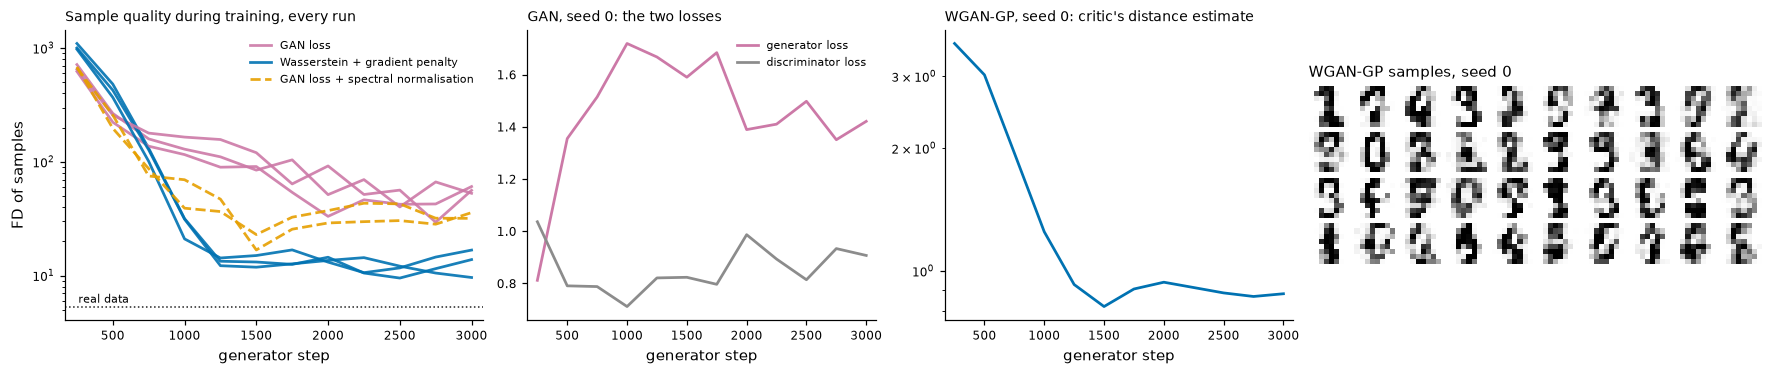

correlation over training between FD and the loss that is being reported:
  GAN, generator loss:         [-0.79, -0.58, -0.41]
  WGAN-GP, critic's estimate:  [0.94, 0.92, 0.92]
  WGAN-GP, from step 1,500 on: [0.07, -0.67, -0.69]


In [12]:
wgans = {seed: gan_run("wgan-gp", seed) for seed in range(3)}
sngans = {seed: gan_run("gan", seed, spectral=True) for seed in range(2)}
for seed, r in wgans.items():
    score(r["samples"], f"WGAN-GP, seed {seed}")
for seed, r in sngans.items():
    score(r["samples"], f"GAN + spectral normalisation, seed {seed}")
display(table([f"GAN, seed {s}" for s in gans] + [f"GAN + spectral normalisation, seed {s}" for s in sngans] + [f"WGAN-GP, seed {s}" for s in wgans]))
print("share of the samples that the judge reads as each digit:")
display(pd.DataFrame({name: G.class_shares(judge, x) for name, x in [("real data", Xte)] + [(f"GAN, seed {s}", gans[s]["samples"]) for s in gans]
                      + [(f"WGAN-GP, seed {s}", wgans[s]["samples"]) for s in wgans]}).T.round(2))
print(f"training time per run: GAN {gans[0]['seconds']:.0f} s, WGAN-GP {wgans[0]['seconds']:.0f} s (five critic steps, each with a second backward pass, per generator step)")
print("WGAN-GP, seed 0, every 500 steps: FD and the critic's estimate of the distance (minus the critic loss)")
display(pd.DataFrame({"FD": wgans[0]["track"]["fd"], "critic's distance estimate": -wgans[0]["track"]["critic loss"]}).loc[::2].T.round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.3), gridspec_kw=dict(width_ratios=[1.2, 1, 1, 1.3]))
ax = axes[0]
for seed in range(3):
    ax.plot(gans[seed]["track"]["fd"], color=viz.PINK, alpha=0.9, label="GAN loss" if seed == 0 else None)
    ax.plot(wgans[seed]["track"]["fd"], color=viz.BLUE, alpha=0.9, label="Wasserstein + gradient penalty" if seed == 0 else None)
for seed in range(2):
    ax.plot(sngans[seed]["track"]["fd"], color=viz.ORANGE, alpha=0.9, ls="--", label="GAN loss + spectral normalisation" if seed == 0 else None)
ax.axhline(ROWS["real data"]["fd"], color=viz.BLACK, ls=":", lw=1); ax.text(260, ROWS["real data"]["fd"] * 1.08, "real data", fontsize=7)
ax.set_yscale("log"); ax.set_xlabel("generator step"); ax.set_ylabel("FD of samples"); ax.set_title("Sample quality during training, every run", fontsize=9); ax.legend(fontsize=7, loc="upper right")
ax = axes[1]
t = gans[0]["track"]; ax.plot(t["generator loss"], color=viz.PINK, label="generator loss"); ax.plot(t["critic loss"], color=viz.GREY, label="discriminator loss")
ax.set_xlabel("generator step"); ax.set_title("GAN, seed 0: the two losses", fontsize=9); ax.legend(fontsize=7, loc="upper right")
ax = axes[2]
t = wgans[0]["track"]; ax.plot(-t["critic loss"], color=viz.BLUE)
ax.set_xlabel("generator step"); ax.set_yscale("log"); ax.set_title("WGAN-GP, seed 0: critic's distance estimate", fontsize=9)
images.show_grid(wgans[0]["samples"][:40], nrow=10, ax=axes[3], title="WGAN-GP samples, seed 0")
plt.show()
corr = lambda a, b: float(np.corrcoef(a, b)[0, 1])
print("correlation over training between FD and the loss that is being reported:")
print("  GAN, generator loss:        ", [round(corr(gans[s]["track"]["fd"], gans[s]["track"]["generator loss"]), 2) for s in range(3)])
print("  WGAN-GP, critic's estimate: ", [round(corr(wgans[s]["track"]["fd"], -wgans[s]["track"]["critic loss"]), 2) for s in range(3)])
print("  WGAN-GP, from step 1,500 on:", [round(corr(wgans[s]["track"]["fd"].loc[1500:], -wgans[s]["track"]["critic loss"].loc[1500:]), 2) for s in range(3)])

**What happened.**

* **Distance to the data.** WGAN-GP reaches an FD of 13.8, 9.6 and 16.8. The GAN loss reached 53 to 61. Every
  WGAN-GP run is better than every GAN run by a factor of three or more.
* **Stability.** In the left panel the three WGAN-GP curves fall together and stay low. The GAN curves wander.
* **Coverage** is better and still poor: 0.41 to 0.57, against 0.27 to 0.39 for the GAN loss and 0.96 for real
  data. In the table of shares, every digit receives at least 2% of the samples in all three WGAN-GP runs.
* **Spectral normalisation** with the GAN loss lies between the two: FD 36 and 32 in two runs.
* **Cost.** A WGAN-GP run took a little over 20 s and a GAN run 5 s (the times are printed above).

**Does the loss say how training is going?** [Arjovsky et al., 2017](https://arxiv.org/abs/1701.07875) argued that the critic's estimate of the distance is
a meaningful training curve, which the GAN loss is not. Our measurements agree in part.

* For the GAN, the generator's loss *rises* while the samples improve (second panel). Over training, the
  correlation between FD and the generator's loss is −0.79, −0.58 and −0.41 in the three runs. The loss reports how
  the contest with the discriminator stands, not how good the samples are.
* For WGAN-GP, the critic's estimate falls together with FD through the large early improvement: the correlation
  over the whole run is 0.92 to 0.94. From step 1,500 on, when FD moves only between roughly 10 and 17, the estimate
  no longer follows it (0.07, −0.67 and −0.69). The curve shows that training is working. It does not show which of
  two late checkpoints is better.

## 8. Autoregressive models: an image as a sequence of pixels

The third family needs no new idea. Any joint distribution factorises by the chain rule, and for an image read
left to right, top to bottom, with pixels $x_1, \dots, x_{64}$:

$$p(x) = \prod_{i=1}^{64} p(x_i \mid x_1, \dots, x_{i-1}).$$

This is exactly the language model of notebooks 01 to 05 with pixels as tokens. PixelRNN and PixelCNN
([Oord et al., 2016](https://arxiv.org/abs/1601.06759)) made it work for images.

### Design choice: each pixel is a discrete choice

A pixel is a number, so the obvious output is one number per pixel with a squared-error loss. That is the choice
that blurred the VAE. [Oord et al., 2016](https://arxiv.org/abs/1601.06759) instead treated each pixel as a **classification over its possible values** (256
for 8-bit images, 17 grey levels here) with a softmax. The model can then say "this pixel is either black or
white, not grey", which a mean cannot express. (PixelCNN++, [Salimans et al., 2017](https://arxiv.org/abs/1701.05517), later replaced the 256-way softmax
with a mixture of logistic distributions, which knows that level 200 is close to level 201.)

Because the model defines $p(x)$ exactly, it has what the GAN lacks: a **likelihood** on held-out data. It is
reported in **bits per pixel**, $-\tfrac{1}{64}\log_2 p(x)$: the average number of bits an ideal compressor built on
the model would need per pixel. Two reference points:

* a model that knows nothing needs $\log_2 17 = 4.09$ bits;
* a model that knows how often each pixel takes each grey level, and nothing about how pixels depend on each other,
  is the image version of the unigram model of notebook 01.

The network is the causal transformer of notebook 03 with one token per pixel and learned positions. We train two
sizes.

width 32, seed 0: 27,922 parameters, 15 s; held-out bits per pixel: best 1.90 at step 550, final 1.90 (training images 1.72)
width 32, seed 1: 27,922 parameters, 15 s; held-out bits per pixel: best 1.90 at step 700, final 1.90 (training images 1.74)
width 32, seed 2: 27,922 parameters, 15 s; held-out bits per pixel: best 1.89 at step 700, final 1.89 (training images 1.72)
width 64, seed 0: 104,850 parameters, 23 s; held-out bits per pixel: best 1.95 at step 300, final 2.28 (training images 1.33)
reference points: uniform 4.09 bits, independent pixels 2.42 bits


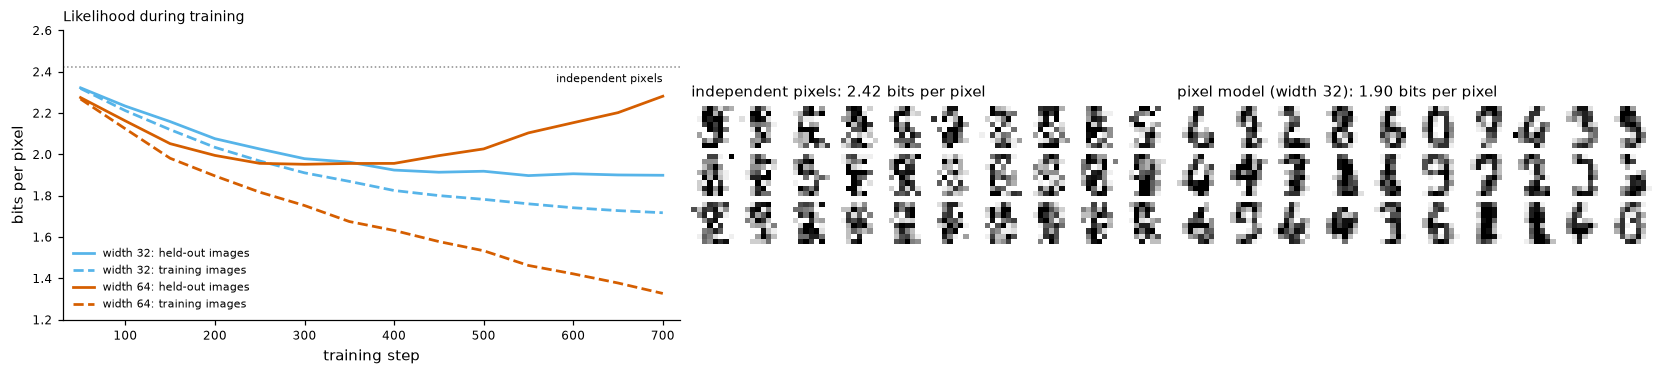

,fd,precision,coverage,nn_ratio,classes,contrast,nfe
model,,,,,,,
real data,5.4,0.96,0.96,1.02,10,0.479,0
independent pixels,126.6,0.74,0.21,1.00,9,0.612,1
"pixel autoregression, seed 0",14.6,0.84,0.79,1.00,10,0.473,64
"pixel autoregression, seed 1",13.7,0.82,0.72,0.98,10,0.482,64
"pixel autoregression, seed 2",20.6,0.82,0.69,0.98,10,0.487,64
"pixel autoregression, width 64",10.9,0.82,0.79,1.00,9,0.475,64


In [13]:
P_ind = G.independent_pixels(Xtr)
bits_ind = G.independent_bits(P_ind, Xte)
ind_samples = G.independent_sample(P_ind, N)
score(ind_samples, "independent pixels", nfe=1)

pix, logs = {}, {}
for name, d, seed in (("width 32, seed 0", 32, 0), ("width 32, seed 1", 32, 1), ("width 32, seed 2", 32, 2), ("width 64, seed 0", 64, 0)):
    t0 = time.time(); set_seed(seed)
    pix[name] = G.PixelAR(d=d, n_layer=2)
    logs[name] = pd.DataFrame(G.train_pixel(pix[name], Xtr, Xte, steps=700, log_every=50, seed=seed)).set_index("step")
    print(f"{name}: {sum(p.numel() for p in pix[name].parameters()):,} parameters, {time.time() - t0:.0f} s; held-out bits per pixel: "
          f"best {logs[name]['test'].min():.2f} at step {logs[name]['test'].idxmin()}, final {logs[name]['test'].iloc[-1]:.2f} (training images {logs[name]['train'].iloc[-1]:.2f})")
print(f"reference points: uniform {math.log2(G.LEVELS):.2f} bits, independent pixels {bits_ind:.2f} bits")
pixel = pix["width 32, seed 0"]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.3), gridspec_kw=dict(width_ratios=[1.3, 1, 1]))
ax = axes[0]
for name, col in (("width 32, seed 0", viz.SKY), ("width 64, seed 0", viz.VERMILION)):
    ax.plot(logs[name]["test"], color=col, label=f"{name[:8]}: held-out images"); ax.plot(logs[name]["train"], color=col, ls="--", label=f"{name[:8]}: training images")
ax.axhline(bits_ind, color=viz.GREY, ls=":", lw=1); ax.text(700, bits_ind - 0.03, "independent pixels", fontsize=7, va="top", ha="right")
ax.set_ylim(1.2, 2.6); ax.set_xlabel("training step"); ax.set_ylabel("bits per pixel"); ax.set_title("Likelihood during training", fontsize=9); ax.legend(fontsize=7, loc="lower left")
images.show_grid(ind_samples[:30], nrow=10, ax=axes[1], title=f"independent pixels: {bits_ind:.2f} bits per pixel")
pixel_samples, fill = pixel.sample(N, seed=0, record=True)
images.show_grid(pixel_samples[:30], nrow=10, ax=axes[2], title=f"pixel model (width 32): {logs['width 32, seed 0']['test'].iloc[-1]:.2f} bits per pixel")
plt.show()
score(pixel_samples, "pixel autoregression, seed 0", nfe=64)
for seed in (1, 2):
    score(pix[f"width 32, seed {seed}"].sample(N, seed=0), f"pixel autoregression, seed {seed}", nfe=64)
score(pix["width 64, seed 0"].sample(N, seed=0), "pixel autoregression, width 64", nfe=64, keep=True)
display(table(["real data", "independent pixels"] + [f"pixel autoregression, seed {s}" for s in range(3)] + ["pixel autoregression, width 64"]))

**What happened.**

* **Likelihood.** The three width-32 models reach 1.89 to 1.90 bits per pixel on held-out images. A model that
  knows nothing needs 4.09 and independent pixels need 2.42, so about half a bit per pixel comes from knowing how
  pixels depend on each other. The samples of the independent model (middle panel) show what that half bit buys:
  each of its pixels is plausible and together they are not a digit (coverage 0.21).
* **Samples.** FD 14.6, 13.7 and 20.6, precision 0.82 to 0.84, coverage 0.69 to 0.79. The contrast is 0.47 to 0.49,
  the same as real images (0.479): no blur. All ten digits are present. nn_ratio is 0.98 to 1.00, so the samples
  are not copies of training images.
* **The wider model overfits, by its likelihood.** At width 64 the held-out likelihood is best at step 300 (1.95
  bits) and then gets worse while the training likelihood keeps improving: 2.28 against 1.33 bits at step 700. A
  model of 105k parameters can begin to learn 1,438 images by heart.
* **Its samples are not worse.** The same overfitted model has the lowest FD of the four (10.9) and an nn_ratio of
  1.00. Held-out likelihood and sample quality are different measurements and can disagree, which [Theis et al., 2015](https://arxiv.org/abs/1511.01844)
  showed in general. This is one model with one seed, and we do not conclude that overfitting helps.

### Sampling is one pixel at a time

To sample, the model is run 64 times: predict the distribution of the first pixel, draw from it, feed the result
back, predict the second, and so on. The animation shows sixteen images being filled in. Pixels not yet drawn are
shown in colour.

saved figures/nb06_pixel_fill.gif  (73 frames, 138 kB)


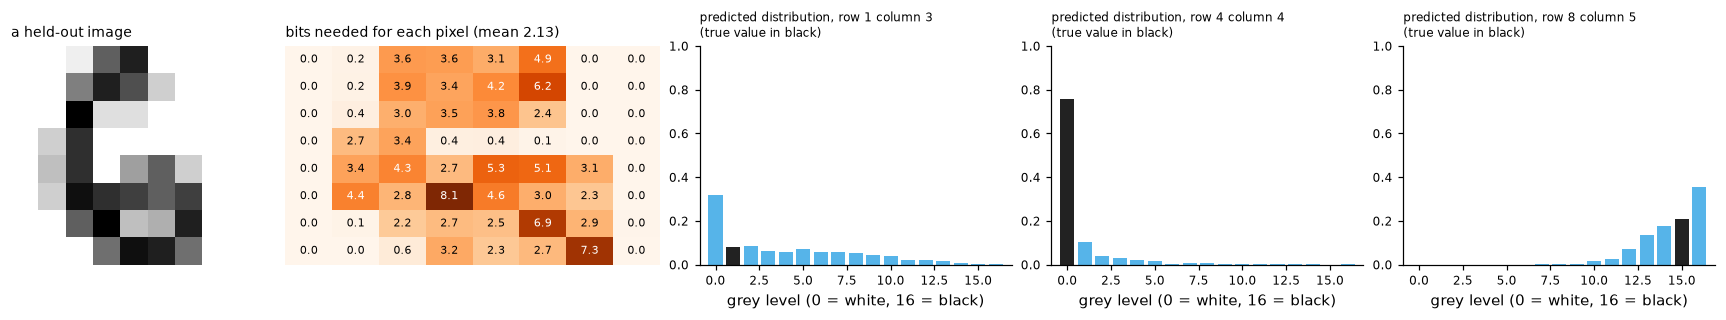

In [14]:
fig, axes = plt.subplots(2, 8, figsize=(11, 3))
cmap = plt.get_cmap("gray_r").copy(); cmap.set_bad(viz.SKY)
def frame(k):
    for j, ax in enumerate(axes.flat):
        ax.clear(); img = np.full(64, np.nan); img[:k] = G.from_levels(fill[k - 1][j]).numpy() if k else []
        ax.imshow(img.reshape(8, 8), cmap=cmap, vmin=-1, vmax=1); ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"pixel {k} of 64: {k} network evaluations so far", fontsize=10)
viz.save_gif(fig, frame, list(range(0, 65)) + [64] * 8, "nb06_pixel_fill.gif", fps=8)

# What the model knows at each pixel: the surprise of the true value, and three of its predicted distributions.
probs = pixel.next_pixel(Xte[:1])[0]                                      # (64, 17): p(pixel i | earlier pixels) for one held-out image
levels = G.to_levels(Xte[:1])[0]
surprise = -torch.log2(probs[torch.arange(64), levels])
fig, axes = plt.subplots(1, 5, figsize=(16, 2.8), gridspec_kw=dict(width_ratios=[1, 1.2, 1, 1, 1]))
axes[0].imshow(Xte[0].view(8, 8), cmap="gray_r", vmin=-1, vmax=1); axes[0].axis("off"); axes[0].set_title("a held-out image", fontsize=9)
viz.heat(axes[1], surprise.view(8, 8).numpy(), annotate=True, fmt="{:.1f}", cmap="Oranges"); axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title(f"bits needed for each pixel (mean {surprise.mean():.2f})", fontsize=9)
for ax, i in zip(axes[2:], (2, 27, 60)):
    ax.bar(range(G.LEVELS), probs[i], color=viz.SKY); ax.bar([int(levels[i])], [float(probs[i, levels[i]])], color=viz.BLACK)
    ax.set_xlabel("grey level (0 = white, 16 = black)"); ax.set_ylim(0, 1); ax.set_title(f"predicted distribution, row {i // 8 + 1} column {i % 8 + 1}\n(true value in black)", fontsize=8)
plt.show()

![Sixteen digits generated one pixel at a time by the autoregressive model, in reading order](figures/nb06_pixel_fill.gif)

**Reading the figures.** The heat map shows where the model is uncertain. Pixels in the empty margins cost 0.0
bits: the model is sure they are white. The cost is in and around the strokes, up to 8.1 bits for a single pixel,
where the exact position of an edge and the exact grey level cannot be predicted. The three bar charts are whole
distributions over the 17 grey levels. In the first row the model cannot yet know which digit this is, and it
spreads its probability over many levels. In the middle of the image it puts most of its probability on white, and
in the last row on the darkest levels, both correctly.

The cost of sampling is the 64 in the last column of the scorecard: one network evaluation per pixel. The same
procedure on a 256×256 colour image needs 196,608.

### Completing an image

An autoregressive model can also continue from a given start, the image version of prompting. We give the model the
top half of held-out digits and let it draw the bottom half, five times each.

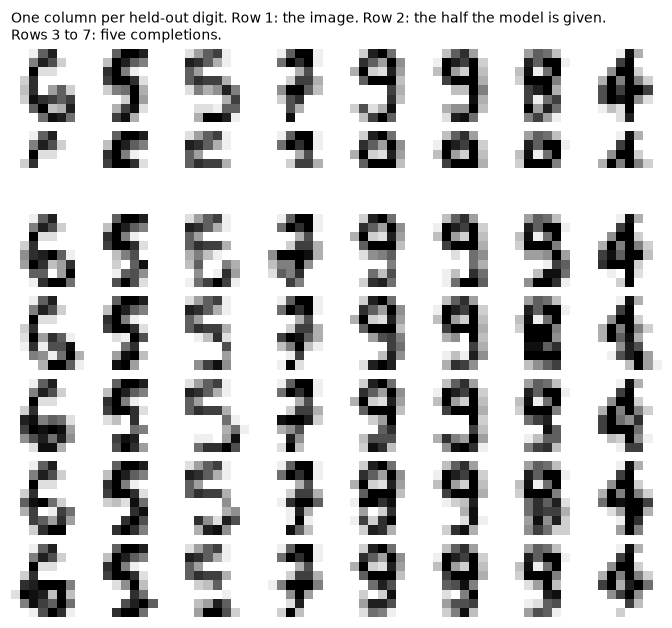

the judge reads the completed image as the original digit: 0.68
the judge reads the top half alone (bottom left blank) as the original digit: 0.23


In [15]:
done = pixel.complete(Xte[:8], keep=32, n=5)
given = Xte[:8].clone(); given[:, 32:] = -1
tiles = torch.cat([Xte[:8], given] + [done[k::5] for k in range(5)])                 # 7 rows of 8: one column per digit
fig, ax = plt.subplots(figsize=(6.5, 5.6))
images.show_grid(tiles, nrow=8, ax=ax)
ax.set_title("One column per held-out digit. Row 1: the image. Row 2: the half the model is given.\nRows 3 to 7: five completions.", fontsize=9)
plt.show()
one = pixel.complete(Xte, keep=32, n=1)
with torch.no_grad():
    blank = Xte.clone(); blank[:, 32:] = -1
    print(f"the judge reads the completed image as the original digit: {float((judge(one).argmax(1) == yte).float().mean()):.2f}")
    print(f"the judge reads the top half alone (bottom left blank) as the original digit: {float((judge(blank).argmax(1) == yte).float().mean()):.2f}")

The five completions of one top half differ from each other, and most are the same digit as the original. Over
all 359 held-out images the judge reads 0.68 of the completed images as the original digit. It reads the top half
alone, with the bottom left blank, as the original digit for 0.23. The remaining third of the completions are a
different digit or no clear digit, which is to be expected where the top half does not determine the digit.

### Try it: temperature and the amount of image given

Static preview at the default settings {'temperature': 1.0, 'rows_given': 4, 'image': 0}. Run the notebook to get the controls.


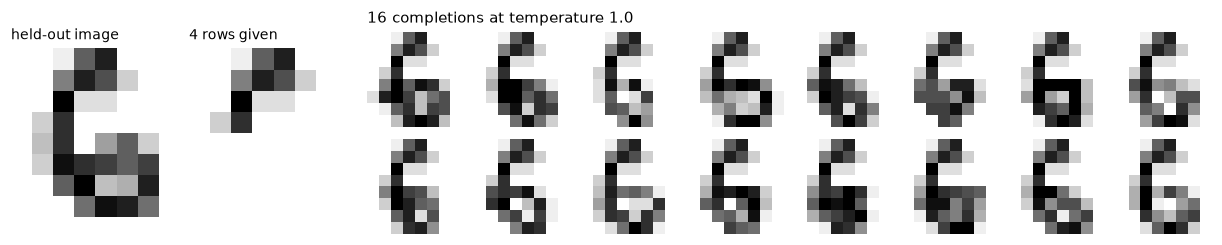

In [16]:
def pixel_explorer(temperature=1.0, rows_given=4, image=0):
    done = pixel.complete(Xte[image:image + 1], keep=8 * rows_given, n=16, seed=0, temperature=temperature)
    given = Xte[image].clone(); given[8 * rows_given:] = -1
    fig, axes = plt.subplots(1, 3, figsize=(11, 2.6), gridspec_kw=dict(width_ratios=[1, 1, 5]))
    axes[0].imshow(Xte[image].view(8, 8), cmap="gray_r", vmin=-1, vmax=1); axes[0].axis("off"); axes[0].set_title("held-out image", fontsize=9)
    axes[1].imshow(given.view(8, 8), cmap="gray_r", vmin=-1, vmax=1); axes[1].axis("off"); axes[1].set_title(f"{rows_given} rows given", fontsize=9)
    images.show_grid(done, nrow=8, ax=axes[2], title=f"16 completions at temperature {temperature:.1f}")
    plt.show()
viz.explore(pixel_explorer, temperature=(0.4, 1.6, 0.1, 1.0), rows_given=(0, 7, 1, 4), image=(0, 50, 1, 0))

## 9. Scorecard: three families, three different failures

,fd,precision,coverage,nn_ratio,classes,contrast,nfe
model,,,,,,,
real data,5.4,0.96,0.96,1.02,10.0,0.479,0.0
"autoencoder, codes from N(0, 1)",179.6,0.54,0.18,0.99,7.0,0.395,1.0
"VAE, KL weight 1, median of 3 seeds",80.1,0.74,0.68,0.97,10.0,0.406,1.0
"VAE, KL weight 0.3, median of 3 seeds",55.3,0.79,0.74,0.96,10.0,0.428,1.0
"GAN, median of 3 seeds",56.2,0.63,0.31,1.01,10.0,0.498,1.0
"WGAN-GP, median of 3 seeds",13.8,0.72,0.47,0.99,10.0,0.481,1.0
"pixel autoregression, median of 3 seeds",14.6,0.82,0.72,0.98,10.0,0.482,64.0


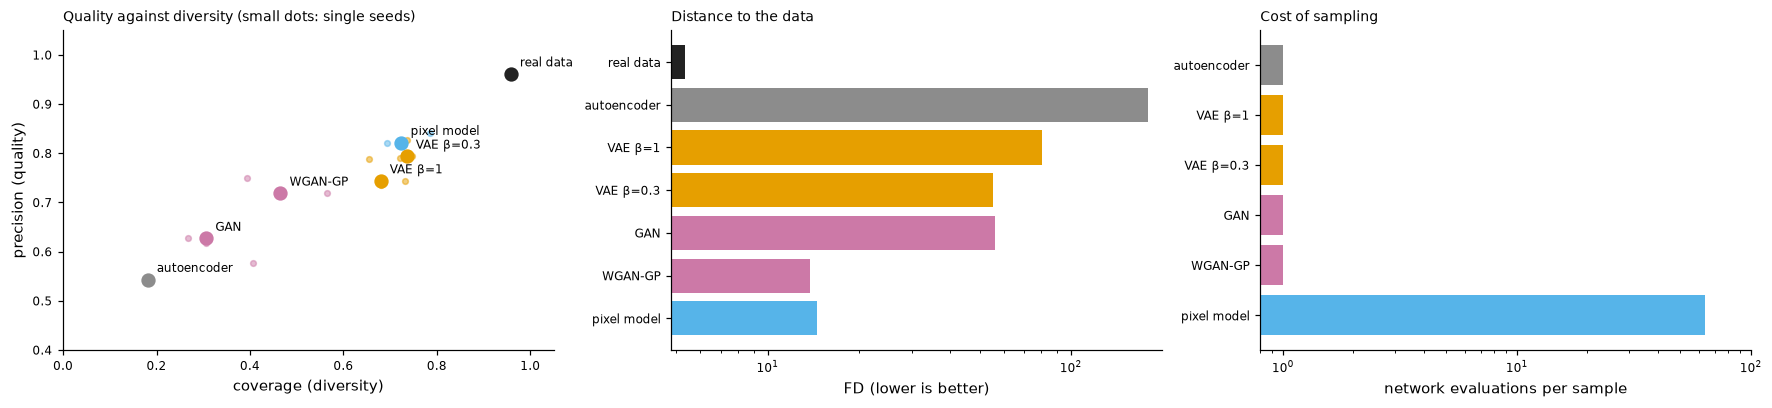

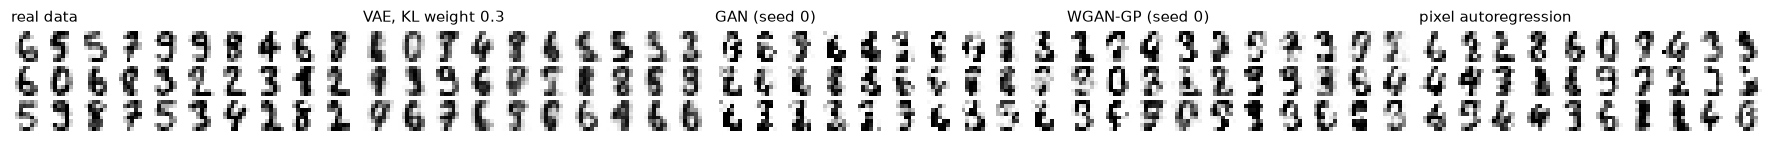

In [17]:
FAMILIES = {"VAE, KL weight 1": ("VAE β=1", viz.ORANGE), "VAE, KL weight 0.3": ("VAE β=0.3", viz.ORANGE), "GAN": ("GAN", viz.PINK),
            "WGAN-GP": ("WGAN-GP", viz.PINK), "pixel autoregression": ("pixel model", viz.SKY)}
family, short = {"real data": viz.BLACK, "autoencoder, codes from N(0, 1)": viz.GREY}, {"real data": "real data", "autoencoder, codes from N(0, 1)": "autoencoder"}
final = ["real data", "autoencoder, codes from N(0, 1)"]
for prefix, (label, colour) in FAMILIES.items():                                     # one row per model: the median of its three seeds
    name = f"{prefix}, median of 3 seeds"
    ROWS[name] = dict(model=name, **{k: float(np.median([ROWS[f"{prefix}, seed {s}"][k] for s in range(3)])) for k in COLS})
    final.append(name); family[name] = colour; short[name] = label
display(table(final))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
ax = axes[0]
for n in final:
    ax.scatter(ROWS[n]["coverage"], ROWS[n]["precision"], s=70, color=family[n], zorder=3)
    ax.annotate(short[n], (ROWS[n]["coverage"], ROWS[n]["precision"]), textcoords="offset points", xytext=(6, 5), fontsize=8)
for prefix, (label, colour) in FAMILIES.items():
    ax.scatter([ROWS[f"{prefix}, seed {s}"]["coverage"] for s in range(3)], [ROWS[f"{prefix}, seed {s}"]["precision"] for s in range(3)], s=14, color=colour, alpha=0.5, zorder=2)
ax.set_xlim(0, 1.05); ax.set_ylim(0.4, 1.05); ax.set_xlabel("coverage (diversity)"); ax.set_ylabel("precision (quality)"); ax.set_title("Quality against diversity (small dots: single seeds)", fontsize=9)
ax = axes[1]
ax.barh([short[n] for n in final][::-1], [ROWS[n]["fd"] for n in final][::-1], color=[family[n] for n in final][::-1])
ax.set_xscale("log"); ax.set_xlabel("FD (lower is better)"); ax.set_title("Distance to the data", fontsize=9)
ax = axes[2]
ax.barh([short[n] for n in final[1:]][::-1], [ROWS[n]["nfe"] for n in final[1:]][::-1], color=[family[n] for n in final[1:]][::-1])
ax.set_xscale("log"); ax.set_xlim(0.8, 100); ax.set_xlabel("network evaluations per sample"); ax.set_title("Cost of sampling", fontsize=9)
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(16, 2.6))
for ax, (name, x) in zip(axes, [("real data", Xte), ("VAE, KL weight 0.3", sweep[0.3]["samples"]), ("GAN (seed 0)", gans[0]["samples"]), ("WGAN-GP (seed 0)", wgans[0]["samples"]), ("pixel autoregression", pixel_samples)]):
    images.show_grid(x[:30], nrow=10, ax=ax, title=name)
plt.show()

rows = [dict(model=n, family="image", **{k: ROWS[n][k] for k in ("fd", "precision", "coverage", "nn_ratio", "nfe")}) for n in final]
metrics.append_rows(rows, "06_image_generators");

**Reading the scorecard.** Each model row is the median of three seeds (the autoencoder is a single run).

| Family | Strength, as measured | Failure, as measured |
|---|---|---|
| VAE | Coverage about 0.7; one network evaluation; training that never failed | Blur: contrast 0.41 to 0.43 against 0.479 for data; FD 55 to 80 |
| GAN | Sharp: contrast 0.50; one network evaluation | Coverage 0.31; precision 0.63, the lowest of the families; FD moved by tens between checkpoints |
| WGAN-GP | FD 13.8 with one network evaluation; consistent across seeds | Coverage 0.47; about four times the training time of the GAN; penalty weight had to be changed on the ring |
| Pixel autoregression | FD 14.6, precision 0.82, coverage 0.72, the best balance here; an exact likelihood | 64 network evaluations per sample |

Three remarks.

* No model is close to real data, which scores 0.96 on both precision and coverage. The highest coverage of any
  model is 0.74.
* The usual summary, "GANs: high quality and low diversity; VAEs: the reverse", is half right here. The low
  diversity of the GAN reproduces. Its samples are sharp, and their precision is the lowest in the table.
* The lead of the pixel model should not be over-read. Its 64 evaluations are for an 8×8 image, and the number
  grows with the number of pixels while the other models stay at one. At useful resolutions that cost was decisive.

What was wanted next: the stable, likelihood-based training and the coverage of the pixel model, the sharpness of
the GAN, and a sampling cost that does not grow with the number of pixels.

## 10. Design choices: what changed, and where these models are today

| Choice | Original | Moved to | Why | Measured here |
|---|---|---|---|---|
| Gradient through a sample | Score-function estimator | Reparameterisation $z = \mu + \sigma\epsilon$ ([Kingma & Welling, 2013](https://arxiv.org/abs/1312.6114)) | Same expectation, far lower variance | Standard deviation of a one-sample gradient estimate: 2.0 against 7.2 |
| Weight of the KL term | $\beta = 1$ | Tuned, or raised from zero during training (KL annealing, [Bowman et al., 2015](https://arxiv.org/abs/1511.06349)) | Too high a price and the code is switched off (posterior collapse) | Best FD at $\beta$ = 0.1 to 0.3 (about 51); $\beta = 10$ switches off all 8 dimensions; annealing kept one more dimension at $\beta = 3$ and none at $\beta = 10$ (Challenge 1) |
| Prior over codes | Fixed $\mathcal{N}(0, I)$ | A second generative model trained on the codes ([Oord et al., 2017](https://arxiv.org/abs/1711.00937), [Rombach et al., 2021](https://arxiv.org/abs/2112.10752)) | The code can then be informative and the decoder sharp | Not tested here; notebook 08 |
| Reconstruction loss | Squared error | Plus perceptual and adversarial terms ([Esser et al., 2020](https://arxiv.org/abs/2012.09841)) | Squared error averages what the code leaves open | The combination is not tested here. Separately: squared error gave contrast 0.41 to 0.43, an adversarial loss 0.50 (data: 0.479) |
| Adversarial loss | Cross-entropy (non-saturating) | Wasserstein distance ([Arjovsky et al., 2017](https://arxiv.org/abs/1701.07875)) | Useful gradient when real and generated do not overlap | Digits: FD 13.8 against 56.2 (medians of three). Ring: 8 of 8 modes kept, against 4 of 8 for the GAN loss at learning rate 0.001 |
| Lipschitz constraint | Weight clipping | Gradient penalty ([Gulrajani et al., 2017](https://arxiv.org/abs/1704.00028)); spectral normalisation ([Miyato et al., 2018](https://arxiv.org/abs/1802.05957)) | Clipping limits the critic too crudely | Weight clipping is not tested. Gradient penalty: FD 13.8, at about four times the training time of the GAN. Spectral normalisation with the GAN loss: FD 32 and 36 |
| Pixel output | One number, squared error | Softmax over values ([Oord et al., 2016](https://arxiv.org/abs/1601.06759)); mixture of logistics ([Salimans et al., 2017](https://arxiv.org/abs/1701.05517)) | A distribution can have two peaks; a mean cannot | Not compared with a squared-error pixel model. Samples of the softmax model have the contrast of the data (0.48) |
| Evaluation | Looking at samples | FID ([Heusel et al., 2017](https://arxiv.org/abs/1706.08500)); precision and coverage ([Naeem et al., 2020](https://arxiv.org/abs/2002.09797)) | One number hides which failure occurred | Section 1: copying, a missing class and blur each show up in a different column |

**Where each family is today.**

| Family | Where it went | In a current system |
|---|---|---|
| VAE | Codes regularised lightly (a very small KL weight) or quantised, with adversarial and perceptual losses on the decoder | The autoencoder inside latent diffusion models such as Stable Diffusion ([Rombach et al., 2021](https://arxiv.org/abs/2112.10752)); notebook 08 |
| GAN | Scaled up through 2021, then displaced as the main generator by diffusion | The adversarial term in those autoencoders ([Esser et al., 2020](https://arxiv.org/abs/2012.09841)); adversarial distillation of diffusion models into few-step samplers |
| Autoregressive | From pixels to learned discrete tokens, then to coarser-to-finer orders and to continuous tokens | Token-based image generators ([Esser et al., 2020](https://arxiv.org/abs/2012.09841), [Tian et al., 2024](https://arxiv.org/abs/2404.02905), [Li et al., 2024](https://arxiv.org/abs/2406.11838)); notebook 10 |

None of the three gave quality, coverage, stable training and cheap sampling together. The next notebook starts on
the model that came closest: diffusion ([Ho et al., 2020](https://arxiv.org/abs/2006.11239)).

## Challenge Problem 1: Can KL annealing prevent posterior collapse?

Section 4 showed code dimensions being switched off at large KL weights. [Bowman et al., 2015](https://arxiv.org/abs/1511.06349) proposed raising the weight from zero to its final value
over the first part of training, so that the code is in use before it has to be paid for. Train a VAE with a 16-number code at KL weights 3 and 10, with
and without annealing over the first 1,000 of 2,000 steps (`anneal=1000` in `G.train_vae`). Report the number of dimensions in use, the reconstruction
error and the KL. Does annealing help, and at which weight?

In [18]:
# Start your code here

### Challenge Problem 1 Solution

In [19]:
out = {}
for beta in (3.0, 10.0):
    for anneal in (0, 1000):
        m = G.VAE(z_dim=16); G.train_vae(m, Xtr, steps=2000, beta=beta, anneal=anneal)
        out[(f"KL weight {beta:g}", "annealed over 1,000 steps" if anneal else "constant weight")] = G.vae_report(m, Xte)
display(pd.DataFrame(out).T.round(2))
# Read the table (one seed per setting). At a KL weight of 3, annealing leaves 4 dimensions in use where a constant
# weight leaves 3, and the reconstruction error is lower (8.63 against 9.60) for a slightly higher KL (1.75 against
# 1.45 nats). At a weight of 10 it changes nothing: no dimension is in use either way.
# Annealing gives the code a head start. It does not change what the final objective prefers, and these results are
# consistent with that: where the final weight makes an empty code the best answer, the code ends empty.

reconstruction error  KL (nats)  latent dimensions in use
KL weight 3  constant weight                            9.60       1.45                       3.0
             annealed over 1,000 steps                  8.63       1.75                       4.0
KL weight 10 constant weight                           18.74       0.00                       0.0
             annealed over 1,000 steps                 18.74       0.00                       0.0

## Challenge Problem 2: Temperature in a pixel model

Language models are usually sampled at a temperature below 1 to trade diversity for quality (the post-training series looks at this in detail).
Does the same trade exist for the pixel model? Sample 359 images from `pixel` at temperatures 0.7, 0.85, 1.0 and 1.15 (`pixel.sample(N, temperature=...)`),
score each with `score(..., keep=False)` and plot precision and coverage against temperature. Which temperature gives the best FD?

In [20]:
# Start your code here

### Challenge Problem 2 Solution

,fd,precision,coverage,nn_ratio,nfe,classes,contrast
temperature,,,,,,,
0.70,59.4,0.87,0.65,0.98,64.0,9.0,0.440
0.85,36.2,0.84,0.82,1.00,64.0,9.0,0.454
1.00,14.6,0.84,0.79,1.00,64.0,10.0,0.473
1.15,13.4,0.77,0.75,0.99,64.0,10.0,0.485


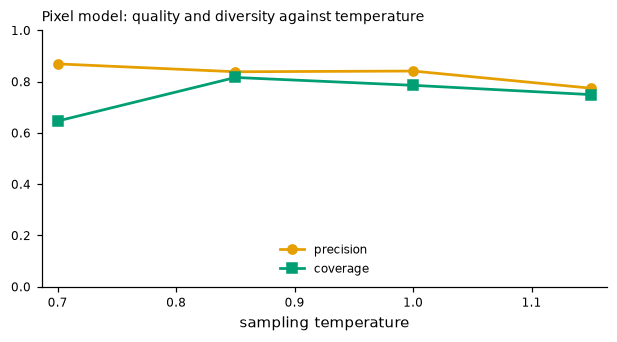

In [21]:
temps = [0.7, 0.85, 1.0, 1.15]
res = pd.DataFrame({t: {k: v for k, v in score(pixel.sample(N, seed=0, temperature=t), f"T={t}", nfe=64, keep=False).items() if k in COLS} for t in temps}).T
res.index.name = "temperature"
display(res.round({"fd": 1, "precision": 2, "coverage": 2, "nn_ratio": 2, "contrast": 3}))
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(temps, res["precision"], "o-", color=viz.ORANGE, label="precision"); ax.plot(temps, res["coverage"], "s-", color=viz.GREEN, label="coverage")
ax.set_xlabel("sampling temperature"); ax.set_ylim(0, 1); ax.legend(fontsize=8, loc="lower center"); ax.set_title("Pixel model: quality and diversity against temperature", fontsize=9); plt.show()
# Read the table (one model). Lowering the temperature to 0.7 raises precision a little (0.87 against 0.84) and costs
# far more than it gains: coverage falls from 0.79 to 0.65 and FD rises from 14.6 to 59.4. The contrast falls too
# (0.440 against 0.473), so the images are flatter.
# FD is lowest at temperatures 1.15 (13.4) and 1.0 (14.6). Those two are closer together than two seeds of the same
# model in section 8 (13.7 to 20.6), so they cannot be told apart. The model's own distribution, temperature 1, is as
# good as any setting tried. The trade of diversity for quality that is routine for text was weak for this model.

## Final summary

* **Scoring.** Samples need several scores. FD measures overall distance. Precision, coverage and nn_ratio each
  catch a failure the others miss: noise and blur, missing classes, copying.
* **Autoencoder.** It compresses well (error 2.73 from 8 numbers) and cannot be sampled (FD 180), because nothing
  says where the codes of real images lie.
* **VAE.** A prior and a noisy code make the decoder samplable. The KL weight sets how much the code may say about
  the image. Too low and the codes leave the prior; too high and the code is switched off, completely at
  $\beta = 10$. The best settings reached an FD of about 51 and still gave soft images.
* **Reparameterisation** is what lets a VAE train by backpropagation: one-sample gradient noise of 2.0 against 7.2
  for the score-function estimator.
* **GAN.** A learned loss removed the blur. Coverage fell to 0.31, precision was the lowest of the families, and
  sample quality moved by tens of FD between checkpoints. On a ring of eight modes, all three runs at a high
  learning rate ended on four.
* **WGAN-GP.** FD 13.8 against 56.2, consistent across seeds, and no mode lost on the ring. It cost about four
  times the training time, and its penalty weight had to be changed from the default on the ring.
* **Pixel autoregression.** The language model of notebooks 01 to 05 applied to pixels: 1.90 bits per pixel
  against 2.42 for independent pixels, sharp samples with a coverage of 0.72, and 64 network evaluations for every
  image. Held-out likelihood and sample quality disagreed about the wider model.
* **What survives.** A lightly regularised autoencoder is the first stage of latent diffusion. The adversarial loss
  trains its decoder. Autoregression over image tokens is an active alternative to diffusion.
* **Next.** Notebook 07 builds the model that replaced all three as the main image generator: diffusion. It is
  trained with a stable regression loss, and it samples in a fixed number of evaluations of the whole image.

## References

* Diederik P Kingma, Max Welling (2013). **Auto-Encoding Variational Bayes**. arXiv:1312.6114. [arxiv.org/abs/1312.6114](https://arxiv.org/abs/1312.6114)
* Samuel R. Bowman, Luke Vilnis, Oriol Vinyals et al. (2015). **Generating Sentences from a Continuous Space**. arXiv:1511.06349. [arxiv.org/abs/1511.06349](https://arxiv.org/abs/1511.06349)
* Ian J. Goodfellow, Jean Pouget-Abadie, Mehdi Mirza et al. (2014). **Generative Adversarial Networks**. arXiv:1406.2661. [arxiv.org/abs/1406.2661](https://arxiv.org/abs/1406.2661)
* Martin Arjovsky, Soumith Chintala, Léon Bottou (2017). **Wasserstein GAN**. arXiv:1701.07875. [arxiv.org/abs/1701.07875](https://arxiv.org/abs/1701.07875)
* Ishaan Gulrajani, Faruk Ahmed, Martin Arjovsky et al. (2017). **Improved Training of Wasserstein GANs**. arXiv:1704.00028. [arxiv.org/abs/1704.00028](https://arxiv.org/abs/1704.00028)
* Takeru Miyato, Toshiki Kataoka, Masanori Koyama et al. (2018). **Spectral Normalization for Generative Adversarial Networks**. arXiv:1802.05957. [arxiv.org/abs/1802.05957](https://arxiv.org/abs/1802.05957)
* Aaron van den Oord, Nal Kalchbrenner, Koray Kavukcuoglu (2016). **Pixel Recurrent Neural Networks**. arXiv:1601.06759. [arxiv.org/abs/1601.06759](https://arxiv.org/abs/1601.06759)
* Tim Salimans, Andrej Karpathy, Xi Chen et al. (2017). **PixelCNN++: Improving the PixelCNN with Discretized Logistic Mixture Likelihood and Other Modifications**. arXiv:1701.05517. [arxiv.org/abs/1701.05517](https://arxiv.org/abs/1701.05517)
* Lucas Theis, Aäron van den Oord, Matthias Bethge (2015). **A note on the evaluation of generative models**. arXiv:1511.01844. [arxiv.org/abs/1511.01844](https://arxiv.org/abs/1511.01844)
* Martin Heusel, Hubert Ramsauer, Thomas Unterthiner et al. (2017). **GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium**. arXiv:1706.08500. [arxiv.org/abs/1706.08500](https://arxiv.org/abs/1706.08500)
* Muhammad Ferjad Naeem, Seong Joon Oh, Youngjung Uh et al. (2020). **Reliable Fidelity and Diversity Metrics for Generative Models**. arXiv:2002.09797. [arxiv.org/abs/2002.09797](https://arxiv.org/abs/2002.09797)
* Aaron van den Oord, Oriol Vinyals, Koray Kavukcuoglu (2017). **Neural Discrete Representation Learning**. arXiv:1711.00937. [arxiv.org/abs/1711.00937](https://arxiv.org/abs/1711.00937)
* Patrick Esser, Robin Rombach, Björn Ommer (2020). **Taming Transformers for High-Resolution Image Synthesis**. arXiv:2012.09841. [arxiv.org/abs/2012.09841](https://arxiv.org/abs/2012.09841)
* Robin Rombach, Andreas Blattmann, Dominik Lorenz et al. (2021). **High-Resolution Image Synthesis with Latent Diffusion Models**. arXiv:2112.10752. [arxiv.org/abs/2112.10752](https://arxiv.org/abs/2112.10752)
* Keyu Tian, Yi Jiang, Zehuan Yuan et al. (2024). **Visual Autoregressive Modeling: Scalable Image Generation via Next-Scale Prediction**. arXiv:2404.02905. [arxiv.org/abs/2404.02905](https://arxiv.org/abs/2404.02905)
* Tianhong Li, Yonglong Tian, He Li et al. (2024). **Autoregressive Image Generation without Vector Quantization**. arXiv:2406.11838. [arxiv.org/abs/2406.11838](https://arxiv.org/abs/2406.11838)
* Jonathan Ho, Ajay Jain, Pieter Abbeel (2020). **Denoising Diffusion Probabilistic Models**. arXiv:2006.11239. [arxiv.org/abs/2006.11239](https://arxiv.org/abs/2006.11239)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).